<a href="https://colab.research.google.com/github/kenth01j/BlueBook/blob/main/Trains_YOLO_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train YOLO Models in Google Colab
**Author:** Evan Juras, [EJ Technology Consultants](https://ejtech.io)

**Last updated:** January 3, 2025

**GitHub:** [Train and Deploy YOLO Models](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models)

# Introduction

This notebook uses [Ultralytics](https://docs.ultralytics.com/) to train YOLO11, YOLOv8, or YOLOv5 object detection models with a custom dataset. At the end of this Colab, you'll have a custom YOLO model that you can run on your PC, phone, or edge device like the Raspberry Pi.

<p align=center>
<img src="https://s3.us-west-1.amazonaws.com/evanjuras.com/img/yolo-model-demo.gif" height="360"><br>
<i>Custom YOLO candy detection model in action!</i>
</p>

I created a YouTube video that walks through this guide step by step. I recommend following along with the video while working through this notebook.

<p align=center>
<a href="https://youtu.be/r0RspiLG260" target="_blank"><img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/Train_YOLO_Thumbnail2.png" height="240"><br>
<i>Click here to go to the video!</i></a>
</p>

**Important note: This notebook will be continuously updated to make sure it works with newer versions of Ultralytics and YOLO. If you see any differences between the YouTube video and this notebook, always follow the notebook!**

### Working in Colab
Colab provides a virtual machine in your browser complete with a Linux OS, filesystem, Python environment, and best of all, a free GPU. We'll install PyTorch and Ultralytics in this environment and use it to train our model. Simply click the Play button on sections of code in this notebook to execute them on the virtual machine.

### Navigation
To navigate this notebook, use the table of contents in the left sidebar to jump from section to section.





**Verify NVIDIA GPU Availability**

Make sure you're using a GPU-equipped machine by going to "Runtime" -> "Change runtime type" in the top menu bar, and then selecting one of the GPU options in the Hardware accelerator section. Click Play on the following code block to verify that the NVIDIA GPU is present and ready for training.

In [1]:
!nvidia-smi

Sun Nov 22 05:03:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
import os

print("Drive directory exists:", os.path.exists("/content/drive"))
print("Drive directory contents:", os.listdir("/content/drive"))

Drive directory exists: True
Drive directory contents: ['MyDrive']


In [14]:
import os

project_path = "/content/drive/MyDrive/yolo"

for item in os.listdir(project_path):
    full_path = os.path.join(project_path, item)

    if os.path.isdir(full_path):
        print(f"\nFOLDER: {item}")
        print(os.listdir(full_path)[:20])
    else:
        print(f"FILE: {item}")


FOLDER: extracted_data
['trained_model']


In [15]:
import os

project_path = "/content/drive/MyDrive/yolo"

print("========== YOLO PROJECT DIRECTORY ==========")

if os.path.exists(project_path):

    for item in os.listdir(project_path):
        full_path = os.path.join(project_path, item)

        if os.path.isdir(full_path):
            print(f"\nFOLDER: {item}")

            for subitem in os.listdir(full_path)[:20]:
                print("   -", subitem)

        else:
            print(f"FILE: {item}")

else:
    print("Project folder not found!")

========== YOLO PROJECT DIRECTORY ==========

FOLDER: extracted_data
   - trained_model


In [8]:
import os

drive_path = "/content/drive/MyDrive"

if os.path.exists(drive_path):
    print("Google Drive is accessible!")
    print("Folders:", os.listdir(drive_path)[:10])
else:
    print("Google Drive is not accessible.")

Google Drive is accessible!
Folders: ['yolo']


In [7]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [9]:
ZIP_PATH = "/content/drive/MyDrive/yolo/data.zip.zip"

import os

print("File exists:", os.path.exists(ZIP_PATH))

File exists: True


In [10]:
import zipfile
import os

EXTRACT_PATH = "/content/drive/MyDrive/yolo/extracted_data"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset successfully extracted!")

Dataset successfully extracted!


In [11]:
for root, dirs, files in os.walk(EXTRACT_PATH):
    level = root.replace(EXTRACT_PATH, '').count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

    for file in files[:10]:
        print(indent + "    " + file)

extracted_data/
    classes.txt
    notes.json
    images/
        0c966e82-725546666_1554329196292039_1166760418560443054_n.jpg
        0cf3d91c-IMG_20260930_121016_-_Copy.jpg
        0d72dd20-IMG_20260930_120959.jpg
        0da36dd2-AdobeStock_201419293.webp
        0dd3e74d-IMG_20260930_121531.jpg
        0e0e26cf-IMG_20260930_130040.jpg
        0e2cb0c9-istockphoto-174662203-612x612.jpg
        0e391b32-IMG_20260930_124252.jpg
        0e51578b-IMG_20260930_121424.jpg
        0ed7ba1c-IMG_20260930_121022_-_Copy.jpg
    labels/
        0002a5ff-IMG_20260930_121742.txt
        00814c5f-727641472_865884816107721_464096325306846257_n.txt
        00c8f29c-pothole-on-asphalt-road-filled-with-rainwater-free-photo.txt
        00ea9ac2-IMG_20260930_120903.txt
        01074905-images_39.txt
        010f8b17-IMG_20260930_121703.txt
        0135878c-IMG_20260930_122200.txt
        01efcb69-images_7.txt
        01fd75c8-IMG_20260930_122733.txt
        01fdfd8a-images_4.txt


In [12]:
CLASSES_PATH = os.path.join(EXTRACT_PATH, "classes.txt")

with open(CLASSES_PATH, "r") as f:
    classes = [line.strip() for line in f if line.strip()]

print("TOTAL CLASSES:", len(classes))
print("\nCLASS DEFINITIONS:")

for index, class_name in enumerate(classes):
    print(f"Class {index}: {class_name}")

TOTAL CLASSES: 3

CLASS DEFINITIONS:
Class 0: Alligator Crack
Class 1: Longitudinal/Transverse crack
Class 2: Potehole


In [13]:
IMAGE_PATH = os.path.join(EXTRACT_PATH, "images")
LABEL_PATH = os.path.join(EXTRACT_PATH, "labels")

image_files = [
    f for f in os.listdir(IMAGE_PATH)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

label_files = [
    f for f in os.listdir(LABEL_PATH)
    if f.lower().endswith('.txt')
]

print("Total images:", len(image_files))
print("Total labels:", len(label_files))
print("Total classes:", len(classes))

Total images: 1438
Total labels: 1497
Total classes: 3


In [14]:
from collections import Counter

class_counts = Counter()
empty_labels = 0
invalid_labels = []

for filename in label_files:

    label_file = os.path.join(LABEL_PATH, filename)

    with open(label_file, "r") as f:
        lines = f.readlines()

    if not lines:
        empty_labels += 1

    for line in lines:
        values = line.strip().split()

        if not values:
            continue

        try:
            class_id = int(values[0])

            if 0 <= class_id < len(classes):
                class_counts[class_id] += 1
            else:
                invalid_labels.append(filename)

        except ValueError:
            invalid_labels.append(filename)

print("ANNOTATION DISTRIBUTION")

for class_id, class_name in enumerate(classes):
    print(f"{class_name}: {class_counts[class_id]} annotations")

print("\nEmpty label files:", empty_labels)
print("Invalid annotations:", len(invalid_labels))


ANNOTATION DISTRIBUTION
Alligator Crack: 428 annotations
Longitudinal/Transverse crack: 648 annotations
Potehole: 965 annotations

Empty label files: 0
Invalid annotations: 0


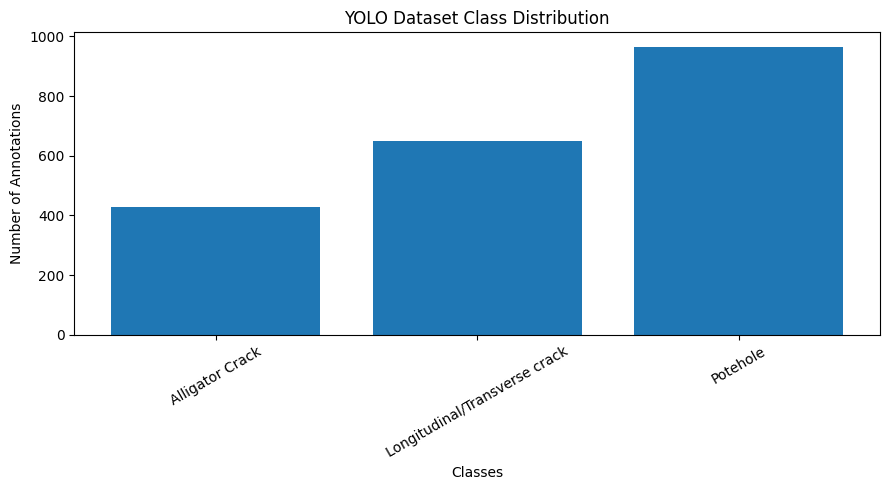

In [15]:
import matplotlib.pyplot as plt

class_names = [classes[i] for i in range(len(classes))]
counts = [class_counts[i] for i in range(len(classes))]

plt.figure(figsize=(9, 5))

plt.bar(class_names, counts)

plt.title("YOLO Dataset Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [16]:
NOTES_PATH = os.path.join(EXTRACT_PATH, "notes.json")

if os.path.exists(NOTES_PATH):
    with open(NOTES_PATH, "r") as f:
        print(f.read())

{
  "categories": [
    {
      "id": 0,
      "name": "Alligator Crack"
    },
    {
      "id": 1,
      "name": "Longitudinal\/Transverse crack"
    },
    {
      "id": 2,
      "name": "Potehole"
    }
  ],
  "info": {
    "year": 2026,
    "version": "1.0",
    "contributor": "Label Studio"
  }
}


In [17]:

import os
from collections import Counter

# Count which classes appear in each image
image_class_counts = Counter()
multi_class_images = []
single_class_images = []
unmatched_images = []

for image_file in image_files:
    base_name = os.path.splitext(image_file)[0]
    label_file = os.path.join(LABEL_PATH, base_name + ".txt")

    if not os.path.exists(label_file):
        unmatched_images.append(image_file)
        continue

    with open(label_file, "r") as f:
        lines = f.readlines()

    image_classes = set()

    for line in lines:
        values = line.strip().split()
        if values:
            image_classes.add(int(values[0]))

    if len(image_classes) == 1:
        class_id = next(iter(image_classes))
        image_class_counts[class_id] += 1
        single_class_images.append((image_file, class_id))

    elif len(image_classes) > 1:
        multi_class_images.append((image_file, sorted(image_classes)))

print("SINGLE-CLASS IMAGE DISTRIBUTION")
for class_id, class_name in enumerate(classes):
    print(f"{class_name}: {image_class_counts[class_id]} images")

print("\nMULTI-CLASS IMAGES:", len(multi_class_images))
print("UNMATCHED IMAGES:", len(unmatched_images))

print("\nSAMPLE MULTI-CLASS IMAGES:")
for item in multi_class_images[:10]:
    print(item)


SINGLE-CLASS IMAGE DISTRIBUTION
Alligator Crack: 418 images
Longitudinal/Transverse crack: 548 images
Potehole: 454 images

MULTI-CLASS IMAGES: 18
UNMATCHED IMAGES: 0

SAMPLE MULTI-CLASS IMAGES:
('12c5311b-728636930_1564861765056425_2256214024810066583_n.jpg', [1, 2])
('163ec28b-728636930_1536551854585291_3813169959679142384_n.jpg', [1, 2])
('1a6783c0-IMG_20260930_122528_1.jpg', [1, 2])
('37055315-IMG_20260930_122526.jpg', [1, 2])
('421bdbd1-727028120_903137038947797_7769547972136486477_n.jpg', [1, 2])
('46d0a6bc-726001793_929687576808018_2464263804421556832_n.jpg', [0, 2])
('4c5c9ae6-IMG_20260930_122530.jpg', [1, 2])
('4dbd479a-IMG_20260930_122526_1.jpg', [1, 2])
('76b79ce8-IMG_20260930_121137.jpg', [0, 2])
('7b7cb640-IMG_20260930_122527.jpg', [1, 2])


In [18]:

import os
import shutil
from collections import Counter

# Destination folder
CLASSIFICATION_PATH = os.path.join(
    EXTRACT_PATH, "classification_dataset"
)

# Create class folders
for class_name in classes:
    folder_name = class_name.replace("/", "_").replace(" ", "_")
    os.makedirs(
        os.path.join(CLASSIFICATION_PATH, folder_name),
        exist_ok=True
    )

# Copy single-class images
copied_counts = Counter()
excluded_images = []

for image_file, class_id in single_class_images:

    class_name = classes[class_id]
    folder_name = class_name.replace("/", "_").replace(" ", "_")

    source = os.path.join(IMAGE_PATH, image_file)
    destination = os.path.join(
        CLASSIFICATION_PATH,
        folder_name,
        image_file
    )

    shutil.copy2(source, destination)
    copied_counts[class_id] += 1

# Report results
print("CLASSIFICATION DATASET CREATED")
print("--------------------------------")

for class_id, class_name in enumerate(classes):
    print(f"{class_name}: {copied_counts[class_id]} images")

print("--------------------------------")
print("Total copied:", sum(copied_counts.values()))
print("Multi-class images excluded:", len(multi_class_images))
print("Unmatched images:", len(unmatched_images))
print("Dataset location:", CLASSIFICATION_PATH)


CLASSIFICATION DATASET CREATED
--------------------------------
Alligator Crack: 418 images
Longitudinal/Transverse crack: 548 images
Potehole: 454 images
--------------------------------
Total copied: 1420
Multi-class images excluded: 18
Unmatched images: 0
Dataset location: /content/drive/MyDrive/yolo/extracted_data/classification_dataset


In [19]:

for class_name in classes:
    folder_name = class_name.replace("/", "_").replace(" ", "_")
    folder_path = os.path.join(CLASSIFICATION_PATH, folder_name)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{class_name}: {len(images)} images")


Alligator Crack: 418 images
Longitudinal/Transverse crack: 548 images
Potehole: 454 images


In [20]:

import os
import shutil
import pandas as pd
from sklearn.model_selection import train_test_split
from collections import Counter

# Set random seed for reproducibility
RANDOM_STATE = 42

# Destination for the split dataset
SPLIT_PATH = os.path.join(EXTRACT_PATH, "split_dataset")

# Collect image paths and their class labels
data = []

for class_id, class_name in enumerate(classes):
    folder_name = class_name.replace("/", "_").replace(" ", "_")
    folder_path = os.path.join(CLASSIFICATION_PATH, folder_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            data.append({
                "filepath": os.path.join(folder_path, filename),
                "class_id": class_id,
                "class_name": class_name,
                "filename": filename
            })

df = pd.DataFrame(data)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df["class_id"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["class_id"]
)

# Remove previous split folder if rerunning
if os.path.exists(SPLIT_PATH):
    shutil.rmtree(SPLIT_PATH)

# Create folders and copy images
splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for split_name, split_df in splits.items():
    for class_name in classes:
        folder_name = class_name.replace("/", "_").replace(" ", "_")
        os.makedirs(
            os.path.join(SPLIT_PATH, split_name, folder_name),
            exist_ok=True
        )

    for _, row in split_df.iterrows():
        folder_name = row["class_name"].replace("/", "_").replace(" ", "_")

        destination = os.path.join(
            SPLIT_PATH,
            split_name,
            folder_name,
            row["filename"]
        )

        shutil.copy2(row["filepath"], destination)

# Display split results
print("DATASET SPLITTING COMPLETE")
print("=" * 50)

for split_name, split_df in splits.items():
    print(f"\n{split_name.upper()}: {len(split_df)} images")

    counts = Counter(split_df["class_name"])

    for class_name in classes:
        print(f"  {class_name}: {counts[class_name]}")

print("\nTOTAL IMAGES:", len(df))
print("DATASET LOCATION:", SPLIT_PATH)


DATASET SPLITTING COMPLETE

TRAIN: 994 images
  Alligator Crack: 293
  Longitudinal/Transverse crack: 383
  Potehole: 318

VALIDATION: 213 images
  Alligator Crack: 62
  Longitudinal/Transverse crack: 83
  Potehole: 68

TEST: 213 images
  Alligator Crack: 63
  Longitudinal/Transverse crack: 82
  Potehole: 68

TOTAL IMAGES: 1420
DATASET LOCATION: /content/drive/MyDrive/yolo/extracted_data/split_dataset


In [21]:

import os
import shutil
import pandas as pd
from sklearn.model_selection import train_test_split
from collections import Counter

# Set random seed for reproducibility
RANDOM_STATE = 42

# Destination for the split dataset
SPLIT_PATH = os.path.join(EXTRACT_PATH, "split_dataset")

# Collect image paths and their class labels
data = []

for class_id, class_name in enumerate(classes):
    folder_name = class_name.replace("/", "_").replace(" ", "_")
    folder_path = os.path.join(CLASSIFICATION_PATH, folder_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            data.append({
                "filepath": os.path.join(folder_path, filename),
                "class_id": class_id,
                "class_name": class_name,
                "filename": filename
            })

df = pd.DataFrame(data)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df["class_id"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["class_id"]
)

# Remove previous split folder if rerunning
if os.path.exists(SPLIT_PATH):
    shutil.rmtree(SPLIT_PATH)

# Create folders and copy images
splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for split_name, split_df in splits.items():
    for class_name in classes:
        folder_name = class_name.replace("/", "_").replace(" ", "_")
        os.makedirs(
            os.path.join(SPLIT_PATH, split_name, folder_name),
            exist_ok=True
        )

    for _, row in split_df.iterrows():
        folder_name = row["class_name"].replace("/", "_").replace(" ", "_")

        destination = os.path.join(
            SPLIT_PATH,
            split_name,
            folder_name,
            row["filename"]
        )

        shutil.copy2(row["filepath"], destination)

# Display split results
print("DATASET SPLITTING COMPLETE")
print("=" * 50)

for split_name, split_df in splits.items():
    print(f"\n{split_name.upper()}: {len(split_df)} images")

    counts = Counter(split_df["class_name"])

    for class_name in classes:
        print(f"  {class_name}: {counts[class_name]}")

print("\nTOTAL IMAGES:", len(df))
print("DATASET LOCATION:", SPLIT_PATH)


DATASET SPLITTING COMPLETE

TRAIN: 994 images
  Alligator Crack: 293
  Longitudinal/Transverse crack: 383
  Potehole: 318

VALIDATION: 213 images
  Alligator Crack: 62
  Longitudinal/Transverse crack: 83
  Potehole: 68

TEST: 213 images
  Alligator Crack: 63
  Longitudinal/Transverse crack: 82
  Potehole: 68

TOTAL IMAGES: 1420
DATASET LOCATION: /content/drive/MyDrive/yolo/extracted_data/split_dataset


In [22]:

from PIL import Image
import os
from collections import Counter

split_names = ["train", "validation", "test"]

image_extensions = (".jpg", ".jpeg", ".png")
dimension_counts = Counter()
image_modes = Counter()
corrupted_images = []
total_checked = 0

for split_name in split_names:
    split_folder = os.path.join(SPLIT_PATH, split_name)

    print(f"\nCHECKING {split_name.upper()} DATASET")
    print("-" * 40)

    for class_name in classes:
        folder_name = class_name.replace("/", "_").replace(" ", "_")
        class_folder = os.path.join(split_folder, folder_name)

        for filename in os.listdir(class_folder):
            if not filename.lower().endswith(image_extensions):
                continue

            image_path = os.path.join(class_folder, filename)
            total_checked += 1

            try:
                with Image.open(image_path) as img:
                    img.verify()

                # Reopen after verify to read dimensions
                with Image.open(image_path) as img:
                    dimension_counts[img.size] += 1
                    image_modes[img.mode] += 1

            except Exception as e:
                corrupted_images.append(image_path)

print("\nIMAGE QUALITY REPORT")
print("=" * 45)
print("Total images checked:", total_checked)
print("Valid images:", total_checked - len(corrupted_images))
print("Corrupted images:", len(corrupted_images))

print("\nMOST COMMON IMAGE DIMENSIONS:")
for dimensions, count in dimension_counts.most_common(10):
    print(f"{dimensions[0]} x {dimensions[1]}: {count} images")

print("\nIMAGE COLOR MODES:")
for mode, count in image_modes.items():
    print(f"{mode}: {count} images")

if corrupted_images:
    print("\nCORRUPTED IMAGE FILES:")
    for path in corrupted_images[:20]:
        print(path)



CHECKING TRAIN DATASET
----------------------------------------

CHECKING VALIDATION DATASET
----------------------------------------

CHECKING TEST DATASET
----------------------------------------

IMAGE QUALITY REPORT
Total images checked: 1420
Valid images: 1420
Corrupted images: 0

MOST COMMON IMAGE DIMENSIONS:
3000 x 4000: 605 images
4000 x 3000: 249 images
2048 x 1536: 222 images
678 x 452: 24 images
547 x 365: 16 images
612 x 406: 12 images
3968 x 2976: 11 images
612 x 407: 10 images
612 x 408: 9 images
766 x 400: 9 images

IMAGE COLOR MODES:
RGB: 1412 images
RGBA: 8 images


In [23]:

import tensorflow as tf
import os

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Model input settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Use the exact class-folder names created earlier
CLASS_NAMES = [
    name.replace("/", "_").replace(" ", "_")
    for name in classes
]

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_PATH, "train"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_PATH, "validation"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

# Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_PATH, "test"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

# Optimize data loading
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Display dataset information
print("\nDATASET PREPARATION COMPLETE")
print("=" * 45)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

print("\nCLASS INDEX MAPPING:")
for index, class_name in enumerate(CLASS_NAMES):
    print(f"{index}: {class_name}")

# Check a sample batch
images, labels = next(iter(train_ds))

print("\nSAMPLE BATCH:")
print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image data type:", images.dtype)

print("\nAVAILABLE GPU:")
print(tf.config.list_physical_devices("GPU"))


Found 994 files belonging to 3 classes.
Found 213 files belonging to 3 classes.
Found 213 files belonging to 3 classes.

DATASET PREPARATION COMPLETE
Image size: (224, 224)
Batch size: 32

CLASS INDEX MAPPING:
0: Alligator_Crack
1: Longitudinal_Transverse_crack
2: Potehole

SAMPLE BATCH:
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image data type: <dtype: 'float32'>

AVAILABLE GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [24]:

import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")

# 2. Load pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# 3. Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax",
    name="classification_output"
)(x)

model = models.Model(inputs, outputs)

# 4. Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Display model architecture
model.summary()

print("\nMODEL CREATED SUCCESSFULLY")
print("Architecture: EfficientNetB0")
print("Pretrained weights: ImageNet")
print("Number of classes:", len(CLASS_NAMES))
print("Trainable base model layers:",
      sum(layer.trainable for layer in base_model.layers))


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


MODEL CREATED SUCCESSFULLY
Architecture: EfficientNetB0
Pretrained weights: ImageNet
Number of classes: 3
Trainable base model layers: 0


In [25]:

import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Save training outputs in Google Drive
RESULTS_PATH = os.path.join(EXTRACT_PATH, "model_results")
os.makedirs(RESULTS_PATH, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    RESULTS_PATH, "best_efficientnetb0.keras"
)

# Callbacks
callbacks = [
    ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Train the model
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("\nTRAINING COMPLETE")
print("Best model saved at:", BEST_MODEL_PATH)


Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5350 - loss: 0.9404
Epoch 1: val_loss improved from None to 0.64778, saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 148s 4s/step - accuracy: 0.6167 - loss: 0.8194 - val_accuracy: 0.7089 - val_loss: 0.6478 - learning_rate: 0.0010
Epoch 2/20
31/32 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.7424 - loss: 0.6016
Epoch 2: val_loss improved from 0.64778 to 0.52949, saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 148s 5s/step - accuracy: 0.7565 - loss: 0.5748 - val_accuracy: 0.7746 - val_loss: 0.5295 - learning_rate: 0.0010
Epoch 3/20
32/32 ━━

In [26]:

import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Save training outputs in Google Drive
RESULTS_PATH = os.path.join(EXTRACT_PATH, "model_results")
os.makedirs(RESULTS_PATH, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    RESULTS_PATH, "best_efficientnetb0.keras"
)

# Callbacks
callbacks = [
    ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Train the model
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("\nTRAINING COMPLETE")
print("Best model saved at:", BEST_MODEL_PATH)


Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9090 - loss: 0.2422
Epoch 1: val_loss improved from None to 0.32215, saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/yolo/extracted_data/model_results/best_efficientnetb0.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 102s 3s/step - accuracy: 0.9044 - loss: 0.2588 - val_accuracy: 0.8826 - val_loss: 0.3222 - learning_rate: 0.0010
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9121 - loss: 0.2607
Epoch 2: val_loss did not improve from 0.32215
32/32 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.9074 - loss: 0.2689 - val_accuracy: 0.8732 - val_loss: 0.3414 - learning_rate: 0.0010
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9164 - loss: 0.2459
Epoch 3: val_loss did not improve from 0.32215
32/32 ━━━━━━━━━━━━━━━━━━━━ 172s 4s/step - accuracy: 0.9014 - loss: 0.2638 - val_accuracy: 0.8638 - val_loss: 0.

7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step
FINAL TEST RESULTS
Test Accuracy:  89.20%
Macro Precision: 89.21%
Macro Recall:    89.37%
Macro F1-score:  89.28%

CLASSIFICATION REPORT
                               precision    recall  f1-score   support

              Alligator_Crack     0.8889    0.8889    0.8889        63
Longitudinal_Transverse_crack     0.8875    0.8659    0.8765        82
                     Potehole     0.9000    0.9265    0.9130        68

                     accuracy                         0.8920       213
                    macro avg     0.8921    0.8937    0.8928       213
                 weighted avg     0.8919    0.8920    0.8918       213



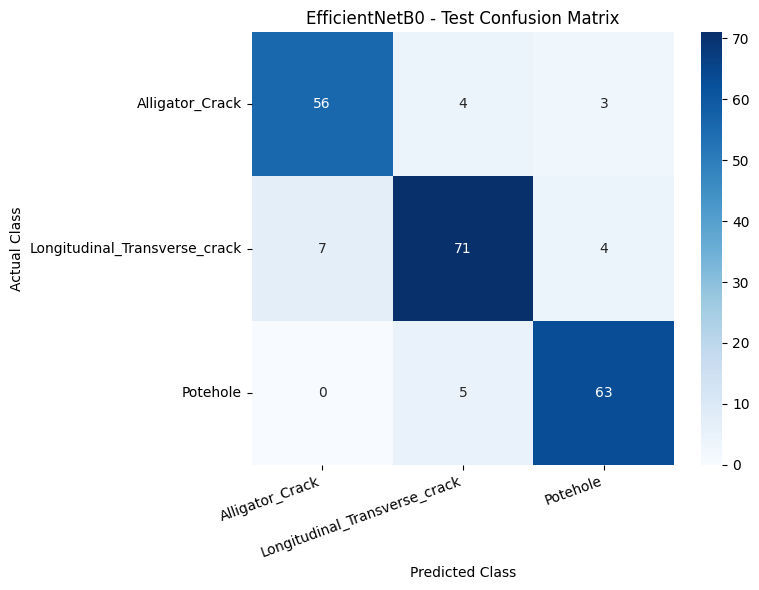


EVALUATION FILES SAVED TO:
/content/drive/MyDrive/yolo/extracted_data/model_results


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Load the best saved model
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Get actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Generate predictions
y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
test_accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro")
recall = recall_score(y_true, y_pred, average="macro")
f1 = f1_score(y_true, y_pred, average="macro")

print("FINAL TEST RESULTS")
print("=" * 50)
print(f"Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall:    {recall * 100:.2f}%")
print(f"Macro F1-score:  {f1 * 100:.2f}%")

# Detailed classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print(report)

# Save classification report
with open(os.path.join(RESULTS_PATH, "classification_report.txt"), "w") as f:
    f.write(report)

# Save metrics
metrics = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "Score": [test_accuracy, precision, recall, f1]
})

metrics.to_csv(
    os.path.join(RESULTS_PATH, "test_metrics.csv"),
    index=False
)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_PATH, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEVALUATION FILES SAVED TO:")
print(RESULTS_PATH)


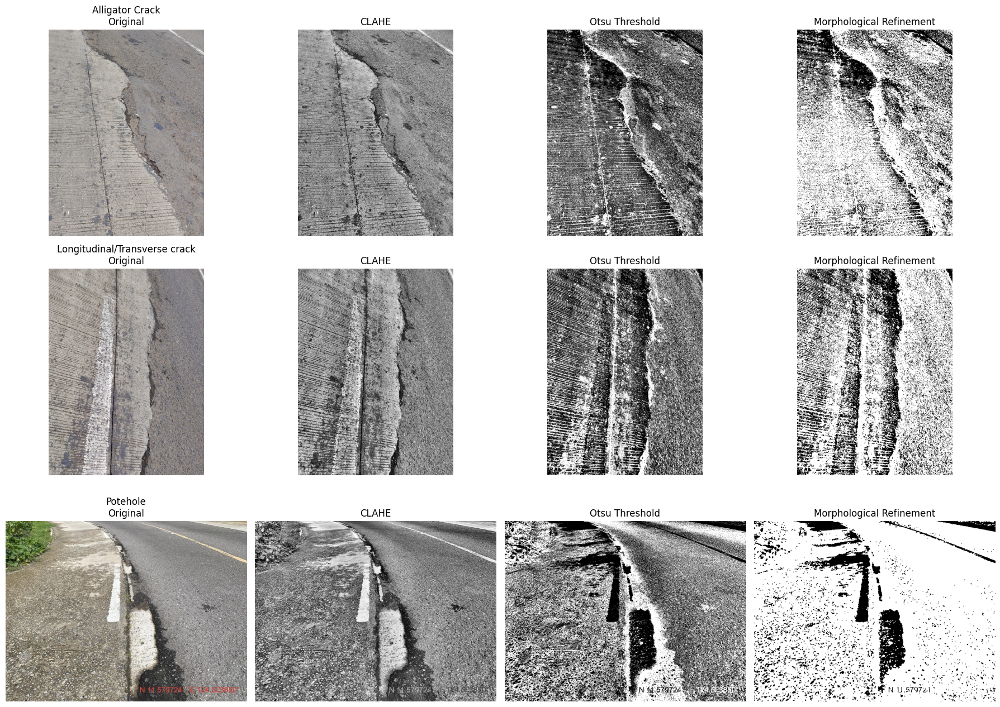

In [28]:

import cv2
import os
import matplotlib.pyplot as plt
import numpy as np

# Get one sample image from each class
sample_images = []

for class_name in classes:
    folder_name = class_name.replace("/", "_").replace(" ", "_")
    folder_path = os.path.join(CLASSIFICATION_PATH, folder_name)

    image_files_in_class = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images.append((
        class_name,
        os.path.join(folder_path, image_files_in_class[0])
    ))

# Display preprocessing stages
fig, axes = plt.subplots(3, 4, figsize=(18, 13))

for row, (class_name, image_path) in enumerate(sample_images):

    # Read original image
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # Convert to grayscale
    gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # 1. CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    # 2. Otsu thresholding
    _, otsu = cv2.threshold(
        enhanced,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # 3. Morphological refinement
    kernel = np.ones((3, 3), np.uint8)

    refined = cv2.morphologyEx(
        otsu,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )

    refined = cv2.morphologyEx(
        refined,
        cv2.MORPH_OPEN,
        kernel,
        iterations=1
    )

    # Display results
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"{class_name}\nOriginal")

    axes[row, 1].imshow(enhanced, cmap="gray")
    axes[row, 1].set_title("CLAHE")

    axes[row, 2].imshow(otsu, cmap="gray")
    axes[row, 2].set_title("Otsu Threshold")

    axes[row, 3].imshow(refined, cmap="gray")
    axes[row, 3].set_title("Morphological Refinement")

    for col in range(4):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


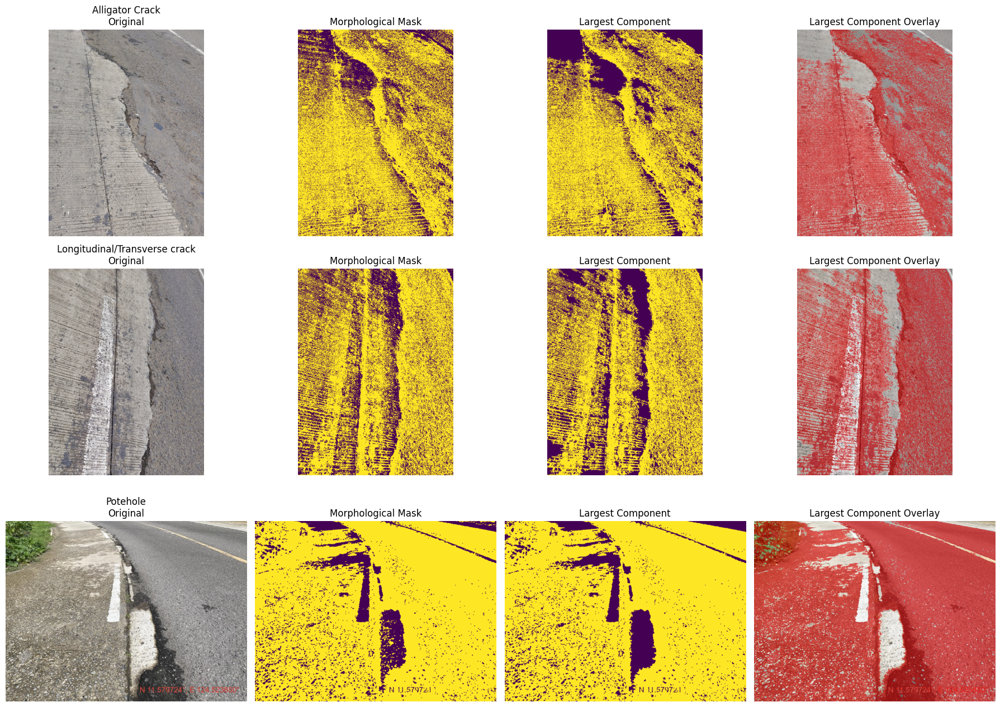

In [29]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

for row, (class_name, image_path) in enumerate(sample_images):

    # Read image
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # Grayscale
    gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(gray)

    # Otsu thresholding
    _, otsu = cv2.threshold(
        enhanced,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Morphological refinement
    kernel = np.ones((3, 3), np.uint8)

    refined = cv2.morphologyEx(
        otsu, cv2.MORPH_CLOSE, kernel, iterations=2
    )
    refined = cv2.morphologyEx(
        refined, cv2.MORPH_OPEN, kernel, iterations=1
    )

    # Connected component analysis
    num_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            refined,
            connectivity=8
        )
    )

    # Select the largest foreground component
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        largest_mask = np.uint8(labels == largest_label) * 255
    else:
        largest_mask = np.zeros_like(refined)

    # Create overlay for visualization
    overlay = original.copy()
    overlay[largest_mask > 0] = (
        0.5 * overlay[largest_mask > 0] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    # Display
    images = [
        original,
        refined,
        largest_mask,
        overlay
    ]

    titles = [
        f"{class_name}\nOriginal",
        "Morphological Mask",
        "Largest Component",
        "Largest Component Overlay"
    ]

    for col in range(4):
        axes[row, col].imshow(images[col])
        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [30]:

import cv2
import os
import pandas as pd

# ROI output directory
ROI_PATH = os.path.join(EXTRACT_PATH, "roi_dataset")

os.makedirs(ROI_PATH, exist_ok=True)

# Padding around each bounding box
PADDING_RATIO = 0.15

roi_records = []
skipped_annotations = 0

for split_name in ["train", "validation", "test"]:

    split_folder = os.path.join(SPLIT_PATH, split_name)

    for class_id, class_name in enumerate(classes):

        folder_name = class_name.replace("/", "_").replace(" ", "_")

        image_folder = os.path.join(split_folder, folder_name)
        output_folder = os.path.join(ROI_PATH, split_name, folder_name)

        os.makedirs(output_folder, exist_ok=True)

        for image_file in os.listdir(image_folder):

            if not image_file.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                continue

            image_path = os.path.join(image_folder, image_file)

            label_file = os.path.join(
                LABEL_PATH,
                os.path.splitext(image_file)[0] + ".txt"
            )

            if not os.path.exists(label_file):
                skipped_annotations += 1
                continue

            image = cv2.imread(image_path)

            if image is None:
                skipped_annotations += 1
                continue

            height, width = image.shape[:2]

            with open(label_file, "r") as f:
                annotations = f.readlines()

            roi_index = 0

            for line in annotations:

                values = line.strip().split()

                if len(values) < 5:
                    continue

                try:
                    annotation_class = int(values[0])

                    # Only use annotations matching the image class
                    if annotation_class != class_id:
                        continue

                    x_center, y_center, box_width, box_height = map(
                        float, values[1:5]
                    )

                except ValueError:
                    continue

                # Convert normalized YOLO coordinates to pixels
                x_center *= width
                y_center *= height
                box_width *= width
                box_height *= height

                x1 = int(x_center - box_width / 2)
                y1 = int(y_center - box_height / 2)
                x2 = int(x_center + box_width / 2)
                y2 = int(y_center + box_height / 2)

                # Add padding
                pad_x = int((x2 - x1) * PADDING_RATIO)
                pad_y = int((y2 - y1) * PADDING_RATIO)

                x1 = max(0, x1 - pad_x)
                y1 = max(0, y1 - pad_y)
                x2 = min(width, x2 + pad_x)
                y2 = min(height, y2 + pad_y)

                # Extract ROI
                roi = image[y1:y2, x1:x2]

                if roi.size == 0 or roi.shape[0] < 2 or roi.shape[1] < 2:
                    skipped_annotations += 1
                    continue

                # Save ROI
                roi_filename = (
                    f"{os.path.splitext(image_file)[0]}_roi_{roi_index}.jpg"
                )

                roi_output_path = os.path.join(
                    output_folder, roi_filename
                )

                cv2.imwrite(roi_output_path, roi)

                roi_records.append({
                    "split": split_name,
                    "class_id": class_id,
                    "class_name": class_name,
                    "source_image": image_file,
                    "roi_filename": roi_filename,
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2
                })

                roi_index += 1

# Save ROI extraction records
roi_df = pd.DataFrame(roi_records)

manifest_path = os.path.join(ROI_PATH, "roi_manifest.csv")
roi_df.to_csv(manifest_path, index=False)

print("ROI EXTRACTION COMPLETE")
print("=" * 50)

if not roi_df.empty:
    print("\nROI DISTRIBUTION:")

    print(
        roi_df.groupby(["split", "class_name"])
        .size()
        .unstack(fill_value=0)
    )

print("\nTotal extracted ROIs:", len(roi_records))
print("Skipped annotations:", skipped_annotations)
print("Manifest:", manifest_path)
print("ROI dataset:", ROI_PATH)


ROI EXTRACTION COMPLETE

ROI DISTRIBUTION:
class_name  Alligator Crack  Longitudinal/Transverse crack  Potehole
split                                                               
test                     64                             88       131
train                   295                            432       620
validation               62                             98       131

Total extracted ROIs: 1921
Skipped annotations: 0
Manifest: /content/drive/MyDrive/yolo/extracted_data/roi_dataset/roi_manifest.csv
ROI dataset: /content/drive/MyDrive/yolo/extracted_data/roi_dataset


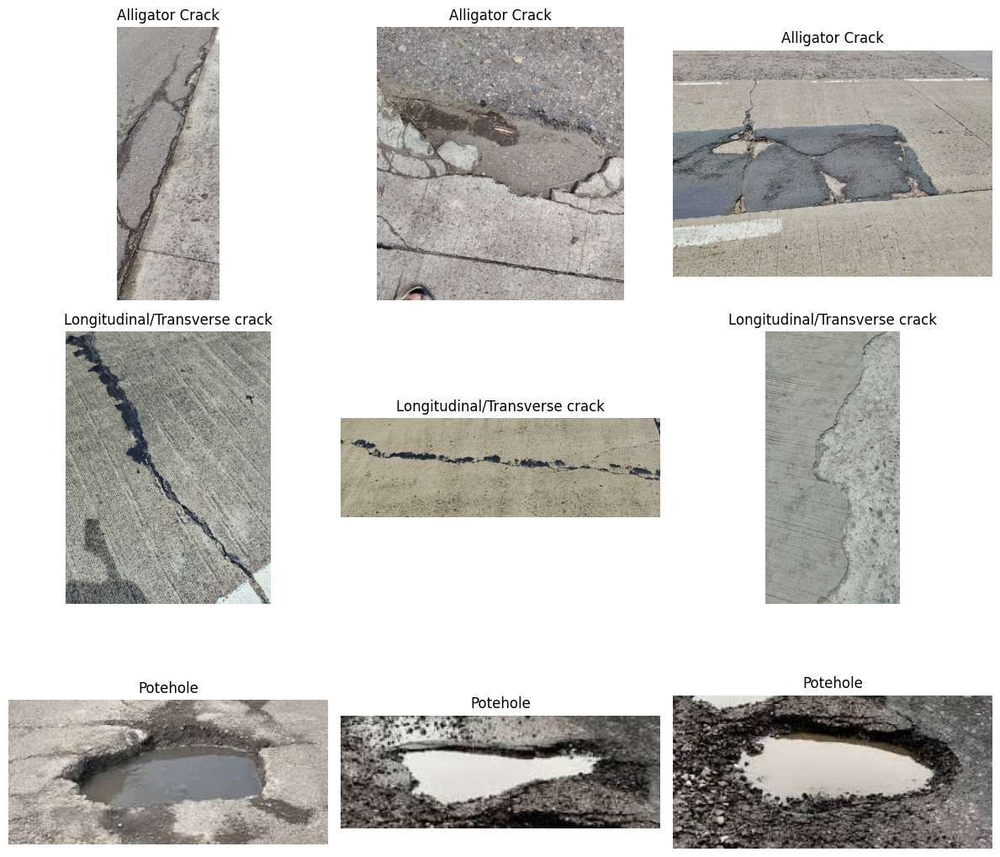

In [31]:

import matplotlib.pyplot as plt
import cv2
import os

# Display up to 3 extracted ROIs per class
fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for row, class_name in enumerate(classes):

    folder_name = class_name.replace("/", "_").replace(" ", "_")

    class_roi_folder = os.path.join(
        ROI_PATH, "train", folder_name
    )

    roi_files = [
        f for f in os.listdir(class_roi_folder)
        if f.lower().endswith(".jpg")
    ][:3]

    for col in range(3):

        axes[row, col].axis("off")

        if col < len(roi_files):

            roi_path = os.path.join(
                class_roi_folder, roi_files[col]
            )

            roi = cv2.imread(roi_path)
            roi = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

            axes[row, col].imshow(roi)
            axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()


In [32]:

import os

# ROI dataset from the previous preprocessing stage
ROI_PATH = "/content/drive/MyDrive/yolo/extracted_data/roi_dataset"

# Background-suppressed output
BACKGROUND_PATH = "/content/drive/MyDrive/yolo/extracted_data/background_suppressed"

os.makedirs(BACKGROUND_PATH, exist_ok=True)

print("CHECKING ROI DATASET")
print("=" * 45)

if not os.path.exists(ROI_PATH):
    print("ERROR: ROI dataset was not found.")
else:
    for folder in sorted(os.listdir(ROI_PATH)):
        folder_path = os.path.join(ROI_PATH, folder)

        if os.path.isdir(folder_path):
            images = [
                f for f in os.listdir(folder_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            print(f"{folder}: {len(images)} ROI images")

print("\nOutput folder:", BACKGROUND_PATH)


CHECKING ROI DATASET
test: 0 ROI images
train: 0 ROI images
validation: 0 ROI images

Output folder: /content/drive/MyDrive/yolo/extracted_data/background_suppressed


In [33]:

import os
import cv2
import numpy as np
from PIL import Image
from tqdm.notebook import tqdm

ROI_PATH = "/content/drive/MyDrive/yolo/extracted_data/roi_dataset"

BACKGROUND_PATH = "/content/drive/MyDrive/yolo/extracted_data/background_suppressed"

os.makedirs(BACKGROUND_PATH, exist_ok=True)

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

def suppress_background(image_path, output_path):
    image = cv2.imread(image_path)

    if image is None:
        return False

    height, width = image.shape[:2]

    # Use a conservative rectangle around the ROI
    margin_x = max(1, int(width * 0.03))
    margin_y = max(1, int(height * 0.03))

    rect = (
        margin_x,
        margin_y,
        max(1, width - 2 * margin_x),
        max(1, height - 2 * margin_y)
    )

    mask = np.zeros((height, width), np.uint8)

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    try:
        cv2.grabCut(
            image,
            mask,
            rect,
            bg_model,
            fg_model,
            5,
            cv2.GC_INIT_WITH_RECT
        )

        # Keep probable and definite foreground
        foreground_mask = np.where(
            (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
            255,
            0
        ).astype(np.uint8)

        # Suppress background using neutral gray
        background = np.full_like(image, 127)

        result = np.where(
            foreground_mask[:, :, np.newaxis] == 255,
            image,
            background
        )

        cv2.imwrite(output_path, result)
        return True

    except Exception as e:
        print("GrabCut error:", image_path, e)
        return False


# Process every class folder
total_processed = 0
total_failed = 0

if not os.path.isdir(ROI_PATH):
    raise FileNotFoundError(
        f"ROI folder not found: {ROI_PATH}"
    )

for class_name in sorted(os.listdir(ROI_PATH)):

    source_folder = os.path.join(ROI_PATH, class_name)

    if not os.path.isdir(source_folder):
        continue

    output_folder = os.path.join(
        BACKGROUND_PATH,
        class_name
    )
    os.makedirs(output_folder, exist_ok=True)

    image_files = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    print(f"\nProcessing {class_name}: {len(image_files)} images")

    for filename in tqdm(image_files):

        source = os.path.join(source_folder, filename)
        destination = os.path.join(output_folder, filename)

        if suppress_background(source, destination):
            total_processed += 1
        else:
            total_failed += 1

print("\nBACKGROUND SUPPRESSION COMPLETE")
print("=" * 45)
print("Successfully processed:", total_processed)
print("Failed:", total_failed)
print("Output folder:", BACKGROUND_PATH)



Processing test: 0 images


0it [00:00, ?it/s]


Processing train: 0 images


0it [00:00, ?it/s]


Processing validation: 0 images


0it [00:00, ?it/s]


BACKGROUND SUPPRESSION COMPLETE
Successfully processed: 0
Failed: 0
Output folder: /content/drive/MyDrive/yolo/extracted_data/background_suppressed


In [34]:

import matplotlib.pyplot as plt
import random

class_folders = [
    f for f in os.listdir(BACKGROUND_PATH)
    if os.path.isdir(os.path.join(BACKGROUND_PATH, f))
]

class_name = class_folders[0]

folder = os.path.join(BACKGROUND_PATH, class_name)

images = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

if images:
    filename = random.choice(images)

    original_path = os.path.join(ROI_PATH, class_name, filename)
    processed_path = os.path.join(BACKGROUND_PATH, class_name, filename)

    original = Image.open(original_path).convert("RGB")
    processed = Image.open(processed_path).convert("RGB")

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original ROI")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(processed)
    plt.title("Background Suppression")
    plt.axis("off")

    plt.show()
else:
    print("No processed images found.")


No processed images found.


In [35]:

import os

BASE_PATH = "/content/drive/MyDrive/yolo/extracted_data"

folders_to_check = [
    "roi_dataset",
    "background_suppressed",
    "classification_dataset",
    "split_dataset"
]

print("DATASET FOLDER DIAGNOSTICS")
print("=" * 55)

for folder in folders_to_check:
    path = os.path.join(BASE_PATH, folder)

    print(f"\nFolder: {folder}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        for root, dirs, files in os.walk(path):
            relative = os.path.relpath(root, path)
            image_files = [
                f for f in files
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png")
                )
            ]

            print(
                f"{relative}: "
                f"{len(image_files)} images"
            )


DATASET FOLDER DIAGNOSTICS

Folder: roi_dataset
Exists: True
.: 0 images
train: 0 images
train/Alligator_Crack: 295 images
train/Longitudinal_Transverse_crack: 432 images
train/Potehole: 620 images
validation: 0 images
validation/Alligator_Crack: 62 images
validation/Longitudinal_Transverse_crack: 98 images
validation/Potehole: 131 images
test: 0 images
test/Alligator_Crack: 64 images
test/Longitudinal_Transverse_crack: 88 images
test/Potehole: 131 images

Folder: background_suppressed
Exists: True
.: 0 images
test: 0 images
train: 0 images
validation: 0 images

Folder: classification_dataset
Exists: True
.: 0 images
Alligator_Crack: 418 images
Longitudinal_Transverse_crack: 548 images
Potehole: 454 images

Folder: split_dataset
Exists: True
.: 0 images
train: 0 images
train/Alligator_Crack: 293 images
train/Longitudinal_Transverse_crack: 383 images
train/Potehole: 318 images
validation: 0 images
validation/Alligator_Crack: 62 images
validation/Longitudinal_Transverse_crack: 83 images


In [37]:

import os
import pandas as pd

ROI_PATH = os.path.join(EXTRACT_PATH, "roi_dataset")
MANIFEST_PATH = os.path.join(ROI_PATH, "roi_manifest.csv")

if not os.path.exists(MANIFEST_PATH):
    raise FileNotFoundError("ROI manifest not found. Check ROI extraction.")

roi_df = pd.read_csv(MANIFEST_PATH)

print("ROI EXTRACTION VERIFICATION")
print("=" * 50)

print("Total ROI images:", len(roi_df))
print("Unique source images:", roi_df["source_image"].nunique())

print("\nROI DISTRIBUTION:")
print(
    roi_df.groupby(["split", "class_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nROI images per source image:")
print(roi_df.groupby("source_image").size().describe())

print("\nManifest exists:", os.path.exists(MANIFEST_PATH))


ROI EXTRACTION VERIFICATION
Total ROI images: 1921
Unique source images: 1420

ROI DISTRIBUTION:
class_name  Alligator Crack  Longitudinal/Transverse crack  Potehole
split                                                               
test                     64                             88       131
train                   295                            432       620
validation               62                             98       131

ROI images per source image:
count    1420.000000
mean        1.352817
std         1.262077
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        16.000000
dtype: float64

Manifest exists: True


In [38]:

import os
import shutil
import pandas as pd

from sklearn.model_selection import train_test_split

# Paths
ROI_PATH = os.path.join(EXTRACT_PATH, "roi_dataset")

NEW_SPLIT_PATH = os.path.join(
    EXTRACT_PATH,
    "roi_dataset_70_10_20"
)

MANIFEST_PATH = os.path.join(
    ROI_PATH,
    "roi_manifest.csv"
)

# Reproducibility
RANDOM_STATE = 42

# Load ROI manifest
roi_df = pd.read_csv(MANIFEST_PATH)

# Check required columns
required_columns = [
    "source_image",
    "class_name",
    "roi_filename",
    "split"
]

assert all(
    col in roi_df.columns for col in required_columns
), "Required manifest columns are missing."

# Each source image must belong to only one class
class_counts = roi_df.groupby("source_image")["class_name"].nunique()

if (class_counts > 1).any():
    raise ValueError(
        "Some source images have multiple classes. "
        "Review these before splitting."
    )

# Create unique source-image dataset
source_df = (
    roi_df[["source_image", "class_name"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("TOTAL SOURCE IMAGES:", len(source_df))

# First split: 70% training, 30% remaining
train_sources, remaining_sources = train_test_split(
    source_df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=source_df["class_name"]
)

# Second split: 10% validation, 20% testing
validation_sources, test_sources = train_test_split(
    remaining_sources,
    test_size=2/3,
    random_state=RANDOM_STATE,
    stratify=remaining_sources["class_name"]
)

# Assign source images to splits
split_mapping = {}

for source in train_sources["source_image"]:
    split_mapping[source] = "train"

for source in validation_sources["source_image"]:
    split_mapping[source] = "validation"

for source in test_sources["source_image"]:
    split_mapping[source] = "test"

# Assign each ROI according to its original source image
roi_df["new_split"] = roi_df["source_image"].map(split_mapping)

if roi_df["new_split"].isna().any():
    raise ValueError("Some ROI images were not assigned a split.")

# Create a fresh output directory
if os.path.exists(NEW_SPLIT_PATH):
    shutil.rmtree(NEW_SPLIT_PATH)

for split in ["train", "validation", "test"]:
    os.makedirs(
        os.path.join(NEW_SPLIT_PATH, split),
        exist_ok=True
    )

# Copy ROI crops into the new split folders
for _, row in roi_df.iterrows():

    split = row["new_split"]
    class_name = row["class_name"]

    source_path = os.path.join(
        ROI_PATH,
        row["split"],
        class_name.replace("/", "_").replace(" ", "_"),
        row["roi_filename"]
    )

    output_folder = os.path.join(
        NEW_SPLIT_PATH,
        split,
        class_name.replace("/", "_").replace(" ", "_")
    )

    os.makedirs(output_folder, exist_ok=True)

    if not os.path.exists(source_path):
        raise FileNotFoundError(
            f"ROI image missing: {source_path}"
        )

    destination = os.path.join(
        output_folder,
        row["roi_filename"]
    )

    shutil.copy2(source_path, destination)

# Save updated manifest
roi_df["original_split"] = roi_df["split"]
roi_df["split"] = roi_df["new_split"]

NEW_MANIFEST_PATH = os.path.join(
    NEW_SPLIT_PATH,
    "roi_manifest_70_10_20.csv"
)

roi_df.to_csv(NEW_MANIFEST_PATH, index=False)

# Display results
print("\n70/10/20 SPLIT COMPLETE")
print("=" * 55)

print("Unique source images:")
print("Training:", len(train_sources))
print("Validation:", len(validation_sources))
print("Testing:", len(test_sources))

print("\nROI image distribution:")
print(
    roi_df.groupby(["new_split", "class_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nTotal ROI images:", len(roi_df))

# Verify no source-image leakage
source_splits = roi_df.groupby("source_image")["new_split"].nunique()

assert source_splits.max() == 1, "DATA LEAKAGE DETECTED!"

print("\nDATA LEAKAGE CHECK: PASSED")
print("Output:", NEW_SPLIT_PATH)


TOTAL SOURCE IMAGES: 1420

70/10/20 SPLIT COMPLETE
Unique source images:
Training: 994
Validation: 142
Testing: 284

ROI image distribution:
class_name  Alligator Crack  Longitudinal/Transverse crack  Potehole
new_split                                                           
test                     83                            126       197
train                   295                            431       593
validation               43                             61        92

Total ROI images: 1921

DATA LEAKAGE CHECK: PASSED
Output: /content/drive/MyDrive/yolo/extracted_data/roi_dataset_70_10_20


In [40]:
import os
import glob
import cv2

folder = os.path.join(
    EXTRACT_PATH,
    "roi_dataset_70_10_20",
    "train",
    "Alligator_Crack"
)

files = glob.glob(os.path.join(folder, "*"))

print("Number of images:", len(files))

for file in files[:5]:
    img = cv2.imread(file)
    if img is not None:
        print(
            os.path.basename(file),
            "| Dimensions:", img.shape,
            "| Size:", round(os.path.getsize(file) / 1024, 2), "KB"
        )
    else:
        print("Could not read:", file)

Number of images: 295
e6963817-IMG_20260930_120854_roi_0.jpg | Dimensions: (3915, 1461, 3) | Size: 2910.01 KB
dcbba4bd-IMG_20260930_122151_roi_0.jpg | Dimensions: (2836, 4000, 3) | Size: 7079.97 KB
5c17a58f-IMG_20260930_124433_roi_0.jpg | Dimensions: (4000, 2881, 3) | Size: 6788.53 KB
111fae0f-IMG_20260930_124109_roi_0.jpg | Dimensions: (3815, 2413, 3) | Size: 4834.75 KB
1d65875f-IMG_20260930_124150_roi_0.jpg | Dimensions: (1910, 2462, 3) | Size: 2542.2 KB


Original dimensions: 1461 x 3915
Processing time: 2.98 seconds
Foreground percentage: 0.0 %
Output dimensions: (3915, 1461, 3)


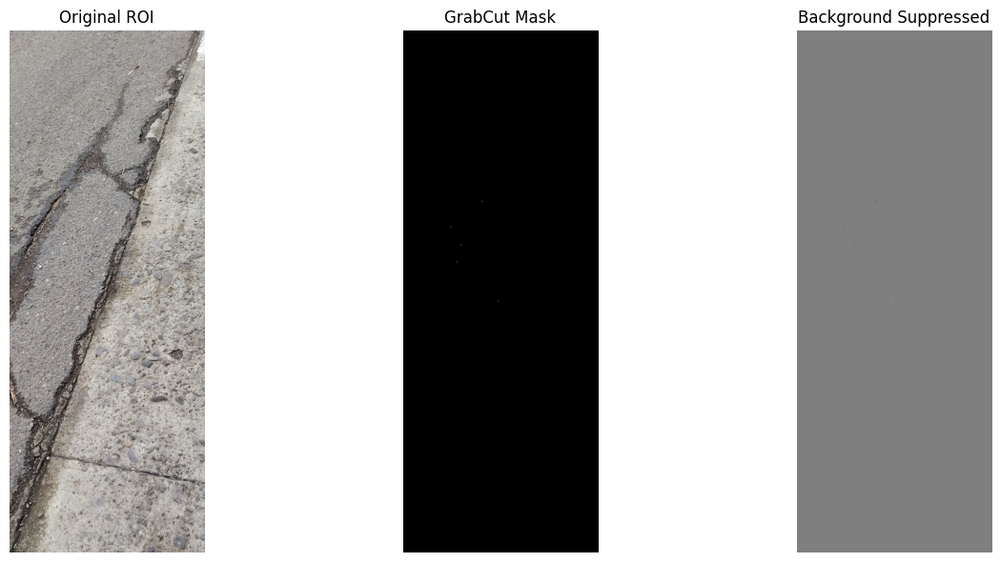

In [41]:
import os
import cv2
import time
import glob
import numpy as np
import matplotlib.pyplot as plt

# Select one training image
folder = os.path.join(
    EXTRACT_PATH,
    "roi_dataset_70_10_20",
    "train",
    "Alligator_Crack"
)

image_files = glob.glob(os.path.join(folder, "*.jpg"))
image_path = image_files[0]

# Load original image
original = cv2.imread(image_path)

if original is None:
    raise ValueError("Could not load image.")

original_h, original_w = original.shape[:2]

print("Original dimensions:", original_w, "x", original_h)

# Resize for faster GrabCut
MAX_SIZE = 800

scale = min(MAX_SIZE / original_w, MAX_SIZE / original_h, 1.0)

small_w = int(original_w * scale)
small_h = int(original_h * scale)

small = cv2.resize(
    original,
    (small_w, small_h),
    interpolation=cv2.INTER_AREA
)

# Initialize GrabCut
mask = np.zeros((small_h, small_w), np.uint8)

margin_x = max(1, int(small_w * 0.03))
margin_y = max(1, int(small_h * 0.03))

rect = (
    margin_x,
    margin_y,
    small_w - 2 * margin_x,
    small_h - 2 * margin_y
)

bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

start = time.time()

cv2.grabCut(
    small,
    mask,
    rect,
    bgd_model,
    fgd_model,
    3,
    cv2.GC_INIT_WITH_RECT
)

elapsed = time.time() - start

# Create foreground mask
foreground_mask = np.where(
    (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

# Restore mask to original dimensions
full_mask = cv2.resize(
    foreground_mask,
    (original_w, original_h),
    interpolation=cv2.INTER_NEAREST
)

# Suppress background using neutral gray
result = original.copy()
result[full_mask == 0] = 127

print("Processing time:", round(elapsed, 2), "seconds")
print("Foreground percentage:", round(np.mean(full_mask > 0) * 100, 2), "%")
print("Output dimensions:", result.shape)

# Display comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original ROI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(full_mask, cmap="gray")
plt.title("GrabCut Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Background Suppressed")
plt.axis("off")

plt.tight_layout()
plt.show()

GrabCut mask values:
(array([0, 2, 3], dtype=uint8), array([ 26336, 212059,      5]))

Foreground pixels: 120
Total pixels: 5719815


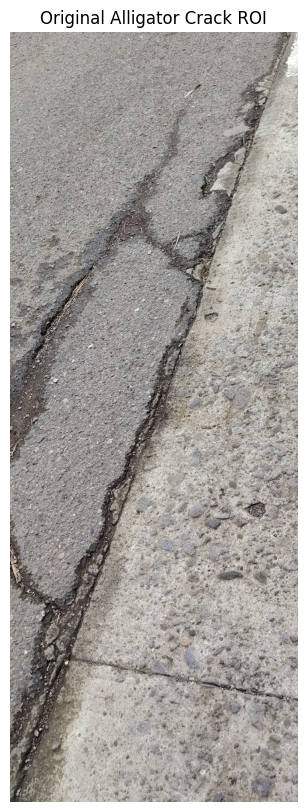

In [42]:
print("GrabCut mask values:")
print(np.unique(mask, return_counts=True))

print("\nForeground pixels:", np.count_nonzero(full_mask))
print("Total pixels:", full_mask.size)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original Alligator Crack ROI")
plt.axis("off")
plt.show()

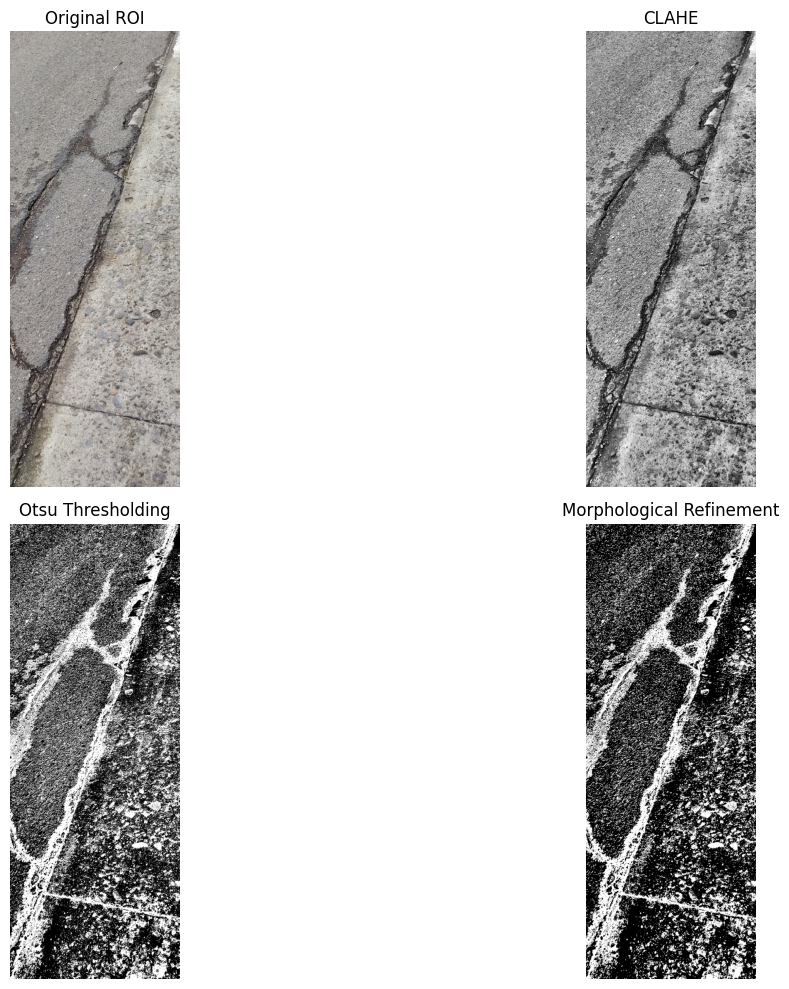

In [43]:
import cv2
import matplotlib.pyplot as plt

# Convert original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Apply CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
enhanced = clahe.apply(gray)

# Apply Otsu thresholding
_, otsu_mask = cv2.threshold(
    enhanced,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Morphological refinement
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (3, 3)
)

refined = cv2.morphologyEx(
    otsu_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Display results
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original ROI")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(enhanced, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(otsu_mask, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(refined, cmap="gray")
plt.title("Morphological Refinement")
plt.axis("off")

plt.tight_layout()
plt.show()

Total connected components: 20291
Largest component area: 696952
Largest component percentage: 12.18 %


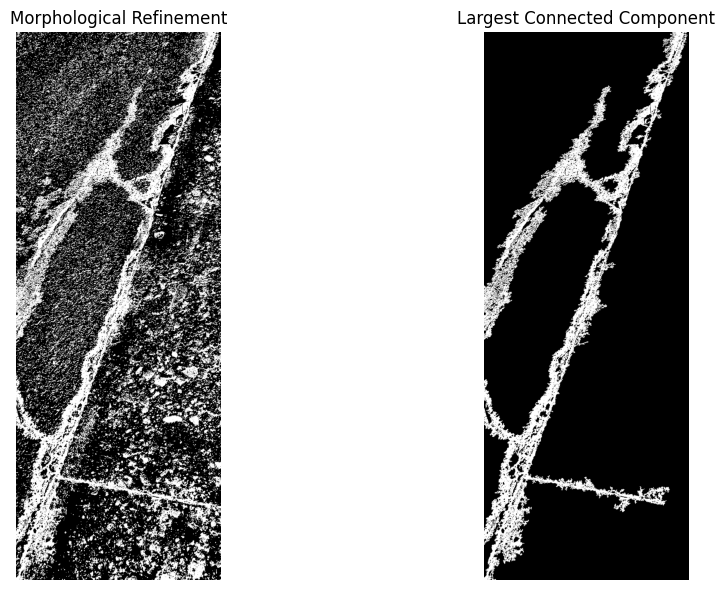

In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Connected component analysis
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        refined,
        connectivity=8
    )
)

# Ignore background (label 0)
if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

    largest_component = np.zeros_like(refined)
    largest_component[labels == largest_label] = 255

    largest_area = stats[largest_label, cv2.CC_STAT_AREA]

    print("Total connected components:", num_labels - 1)
    print("Largest component area:", largest_area)
    print(
        "Largest component percentage:",
        round(largest_area / refined.size * 100, 2),
        "%"
    )
else:
    largest_component = np.zeros_like(refined)
    print("No foreground components detected.")

# Display
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(refined, cmap="gray")
plt.title("Morphological Refinement")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(largest_component, cmap="gray")
plt.title("Largest Connected Component")
plt.axis("off")

plt.tight_layout()
plt.show()

In [45]:
import pandas as pd

component_data = []

for i in range(1, num_labels):
    component_data.append({
        "Component": i,
        "Area": stats[i, cv2.CC_STAT_AREA],
        "Width": stats[i, cv2.CC_STAT_WIDTH],
        "Height": stats[i, cv2.CC_STAT_HEIGHT],
        "X": stats[i, cv2.CC_STAT_LEFT],
        "Y": stats[i, cv2.CC_STAT_TOP]
    })

component_df = pd.DataFrame(component_data)

component_df = component_df.sort_values(
    by="Area",
    ascending=False
)

print("TOP 10 CONNECTED COMPONENTS")
display(component_df.head(10))

TOP 10 CONNECTED COMPONENTS


,Component,Area,Width,Height,X,Y
57,58,696952,1449,3915,0,0
19882,19883,13599,152,160,1203,3755
18871,18872,11563,179,201,999,3370
15163,15164,11519,268,144,980,2393
19889,19890,10757,186,156,987,3759
7763,7764,9827,226,226,102,1114
8033,8034,9709,259,139,1201,1173
19396,19397,8512,119,203,1269,3574
16565,16566,8323,229,140,1232,2676
14666,14667,7764,137,193,1324,2301


In [46]:
import os

ROI_SPLIT_PATH = os.path.join(
    EXTRACT_PATH,
    "roi_dataset_70_10_20"
)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(ROI_SPLIT_PATH, split)

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

            print(f"{class_name}: {count} images")


TRAIN
Alligator_Crack: 295 images
Longitudinal_Transverse_crack: 431 images
Potehole: 593 images

VALIDATION
Alligator_Crack: 43 images
Longitudinal_Transverse_crack: 61 images
Potehole: 92 images

TEST
Alligator_Crack: 83 images
Longitudinal_Transverse_crack: 126 images
Potehole: 197 images


In [47]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Image configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Class names in the correct order
CLASS_NAMES = [
    "Alligator_Crack",
    "Longitudinal_Transverse_crack",
    "Potehole"
]

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(ROI_SPLIT_PATH, "train"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

# Load validation dataset
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(ROI_SPLIT_PATH, "validation"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(ROI_SPLIT_PATH, "test"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
], name="road_damage_augmentation")

print("\nDATASETS LOADED SUCCESSFULLY")
print("Classes:", CLASS_NAMES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


Found 1319 files belonging to 3 classes.
Found 196 files belonging to 3 classes.
Found 406 files belonging to 3 classes.

DATASETS LOADED SUCCESSFULLY
Classes: ['Alligator_Crack', 'Longitudinal_Transverse_crack', 'Potehole']
Image size: (224, 224)
Batch size: 32


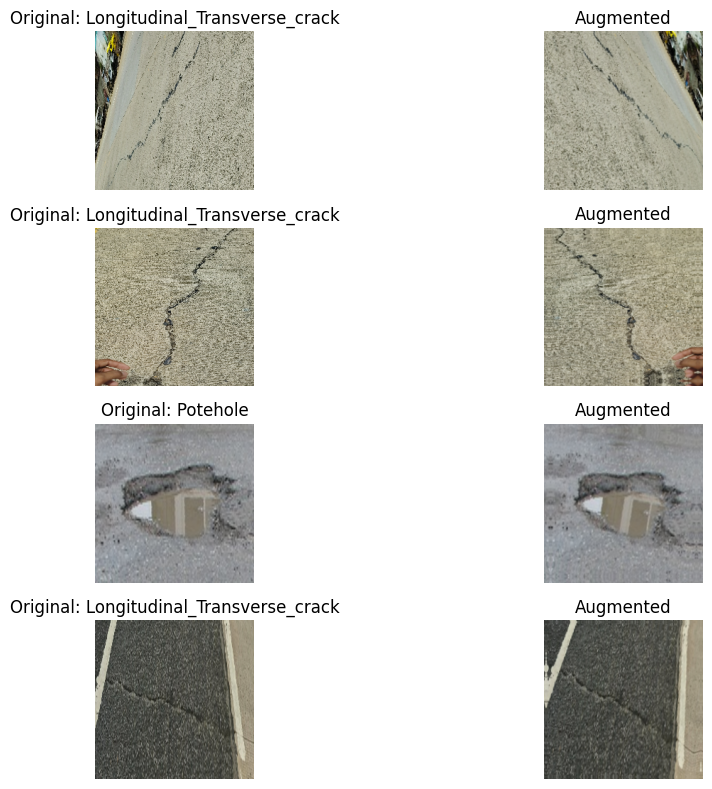

In [48]:

# Get one training batch
images, labels = next(iter(train_dataset))

# Apply augmentation
augmented_images = data_augmentation(
    images,
    training=True
)

# Display original and augmented images
plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("Original: " + CLASS_NAMES[labels[i].numpy()])
    plt.axis("off")

    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(
        tf.clip_by_value(
            augmented_images[i], 0, 255
        ).numpy().astype("uint8")
    )
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [49]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Training class labels
y_train = np.concatenate([
    labels.numpy()
    for _, labels in train_dataset
])

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(np.unique(y_train), weights)
}

print("CLASS WEIGHTS")
for class_id, weight in class_weights.items():
    print(f"{CLASS_NAMES[class_id]}: {weight:.4f}")

print("\nTraining samples:", len(y_train))
print("Number of classes:", len(class_weights))


CLASS WEIGHTS
Alligator_Crack: 1.4904
Longitudinal_Transverse_crack: 1.0201
Potehole: 0.7414

Training samples: 1319
Number of classes: 3


In [50]:

import tensorflow as tf

print("TENSORFLOW ENVIRONMENT")
print("======================")
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("\nGPU is available. Ready for model development.")
else:
    print("\nWARNING: No GPU detected.")
    print("Enable T4 GPU under Runtime > Change runtime type.")


TENSORFLOW ENVIRONMENT
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU is available. Ready for model development.


In [51]:

import importlib.util
import tensorflow as tf

print("MODEL LIBRARY CHECK")
print("===================")

packages = [
    "keras_hub",
    "keras_cv",
    "transformers",
    "torch",
    "torchvision"
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if available else 'Not installed'}")

print("\nGPU DETAILS")
for gpu in tf.config.list_physical_devices("GPU"):
    print(gpu)

print("\nGPU MEMORY INFORMATION")
try:
    print(tf.config.experimental.get_memory_info("GPU:0"))
except Exception as e:
    print("Memory information unavailable:", e)


MODEL LIBRARY CHECK
keras_hub: Available
keras_cv: Not installed
transformers: Available
torch: Available
torchvision: Available

GPU DETAILS
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

GPU MEMORY INFORMATION
{'current': 79775488, 'peak': 687467008}


In [52]:

import keras_hub

print("KERAS HUB VERSION:", keras_hub.__version__)

print("\nAVAILABLE VISION TRANSFORMER PRESETS")
print("====================================")

presets = keras_hub.models.ViTBackbone.presets

vit_presets = [
    name for name in presets.keys()
    if "vit" in name.lower()
]

for name in vit_presets:
    print(name)

print("\nTOTAL VIT PRESETS:", len(vit_presets))


KERAS HUB VERSION: 0.26.0

AVAILABLE VISION TRANSFORMER PRESETS
vit_base_patch16_224_imagenet
vit_base_patch16_384_imagenet
vit_large_patch16_224_imagenet
vit_large_patch16_384_imagenet
vit_base_patch32_384_imagenet
vit_large_patch32_384_imagenet
vit_base_patch16_224_imagenet21k
vit_base_patch32_224_imagenet21k
vit_huge_patch14_224_imagenet21k
vit_large_patch16_224_imagenet21k
vit_large_patch32_224_imagenet21k

TOTAL VIT PRESETS: 11


In [53]:

import keras_hub
import tensorflow as tf

VIT_PRESET = "vit_base_patch16_224_imagenet"

print("Loading pretrained ViT-B16...")

# Load pretrained Vision Transformer
vit_backbone = keras_hub.models.ViTBackbone.from_preset(
    VIT_PRESET
)

# Load matching image preprocessing
vit_preprocessor = (
    keras_hub.models.ViTImageClassifierPreprocessor.from_preset(
        VIT_PRESET
    )
)

# Freeze pretrained weights initially
vit_backbone.trainable = False

print("\nViT-B16 loaded successfully!")

# Test using one training image
sample_images, sample_labels = next(iter(train_dataset))
sample_image = sample_images[:1]

# Apply ViT-specific preprocessing
vit_input = vit_preprocessor(sample_image)

# Extract transformer features
vit_features = vit_backbone(vit_input, training=False)

print("\nVIT TEST RESULTS")
print("================")
print("Input image shape:", sample_image.shape)
print("Preprocessed shape:", vit_input.shape)
print("ViT feature shape:", vit_features.shape)
print("Backbone trainable:", vit_backbone.trainable)
print("Number of parameters:", vit_backbone.count_params())


Loading pretrained ViT-B16...

ViT-B16 loaded successfully!

VIT TEST RESULTS
Input image shape: (1, 224, 224, 3)
Preprocessed shape: (1, 224, 224, 3)
ViT feature shape: (1, 197, 768)
Backbone trainable: False
Number of parameters: 85798656


In [55]:

import tensorflow as tf

print("Loading pretrained EfficientNetB0...")

# Load EfficientNetB0
efficientnet = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg"
)

# Freeze pretrained weights initially
efficientnet.trainable = False

# Test feature extraction
sample_images, sample_labels = next(iter(train_dataset))
sample_image = sample_images[:1]

# Extract CNN features
cnn_features = efficientnet(
    sample_image,
    training=False
)

print("\nEFFICIENTNETB0 TEST RESULTS")
print("==========================")
print("Input image shape:", sample_image.shape)
print("CNN feature shape:", cnn_features.shape)
print("Backbone trainable:", efficientnet.trainable)
print("Number of parameters:", efficientnet.count_params())


Loading pretrained EfficientNetB0...

EFFICIENTNETB0 TEST RESULTS
Input image shape: (1, 224, 224, 3)
CNN feature shape: (1, 1280)
Backbone trainable: False
Number of parameters: 4049571


In [56]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# --------------------------------------------------
# 1. INPUT
# --------------------------------------------------

inputs = layers.Input(
    shape=(224, 224, 3),
    name="road_damage_image"
)

# Augmentation is applied only during training
augmented = data_augmentation(inputs)

# --------------------------------------------------
# 2. EFFICIENTNETB0 BRANCH
# --------------------------------------------------

cnn_features = efficientnet(
    augmented,
    training=False
)

cnn_projection = layers.Dense(
    256,
    activation="relu",
    name="cnn_projection"
)(cnn_features)

cnn_projection = layers.LayerNormalization()(
    cnn_projection
)

# --------------------------------------------------
# 3. VIT-B16 BRANCH
# --------------------------------------------------

vit_input = vit_preprocessor(augmented)

vit_tokens = vit_backbone(
    vit_input,
    training=False
)

# Extract CLS token (first token)
vit_cls = layers.Lambda(
    lambda x: x[:, 0, :],
    name="vit_cls_token"
)(vit_tokens)

vit_projection = layers.Dense(
    256,
    activation="relu",
    name="vit_projection"
)(vit_cls)

vit_projection = layers.LayerNormalization()(
    vit_projection
)

# --------------------------------------------------
# 4. ADAPTIVE FEATURE FUSION
# --------------------------------------------------

combined_features = layers.Concatenate()([
    cnn_projection,
    vit_projection
])

# Learnable feature-wise fusion gate
fusion_weights = layers.Dense(
    256,
    activation="sigmoid",
    name="adaptive_fusion_gate"
)(combined_features)

# Weighted feature combination
cnn_weighted = layers.Multiply()([
    fusion_weights,
    cnn_projection
])

vit_complement = layers.Lambda(
    lambda x: 1.0 - x,
    name="complementary_gate"
)(fusion_weights)

vit_weighted = layers.Multiply()([
    vit_complement,
    vit_projection
])

fused_features = layers.Add(name="adaptive_fusion")([
    cnn_weighted,
    vit_weighted
])

# --------------------------------------------------
# 5. CLASSIFICATION HEAD
# --------------------------------------------------

x = layers.Dense(
    128,
    activation="relu"
)(fused_features)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    3,
    activation="softmax",
    name="road_damage_classification"
)(x)

# --------------------------------------------------
# 6. CREATE HYBRID MODEL
# --------------------------------------------------

hybrid_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_ViT_B16_Hybrid"
)

# --------------------------------------------------
# 7. COMPILE
# --------------------------------------------------

hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------------
# 8. TEST MODEL
# --------------------------------------------------

print("HYBRID MODEL SUMMARY")
print("====================")

hybrid_model.summary()

test_images, test_labels = next(iter(train_dataset))

predictions = hybrid_model(
    test_images[:2],
    training=False
)

print("\nFORWARD PASS TEST")
print("=================")
print("Input shape:", test_images[:2].shape)
print("Prediction shape:", predictions.shape)
print("Predicted probabilities:")
print(predictions.numpy())
print("\nModel successfully constructed!")


HYBRID MODEL SUMMARY


Model: "EfficientNetB0_ViT_B16_Hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ road_damage_image   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ road_damage_augmen… │ (None, 224, 224,  │          0 │ road_damage_imag… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vi_t_image_classif… │ (None, 224, 224,  │          0 │ road_damage_augm… │
│ (ViTImageClassifie… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vi_t_backbone       │ (None, 197, 768)  │ 85,798,656 │ vi_t_image_class… │
│ (ViTBackbone)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ road_damage_augm… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vit_cls_token       │ (None, 768)       │          0 │ vi_t_backbone[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_projection      │ (None, 256)       │    327,936 │ efficientnetb0[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vit_projection      │ (None, 256)       │    196,864 │ vit_cls_token[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 256)       │        512 │ cnn_projection[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256)       │        512 │ vit_projection[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 512)       │          0 │ layer_normalizat… │
│ (Concatenate)       │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ adaptive_fusion_ga… │ (None, 256)       │    131,328 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ complementary_gate  │ (None, 256)       │          0 │ adaptive_fusion_… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 256)       │          0 │ adaptive_fusion_… │
│                     │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 256)       │          0 │ complementary_ga… │
│ (Multiply)          │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ adaptive_fusion     │ (None, 256)       │          0 │ multiply[0][0],   │
│ (Add)               │                   │            │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     32,896 │ adaptive_fusion[

 Total params: 90,538,662 (345.38 MB)

 Trainable params: 690,435 (2.63 MB)

 Non-trainable params: 89,848,227 (342.74 MB)


FORWARD PASS TEST
Input shape: (2, 224, 224, 3)
Prediction shape: (2, 3)
Predicted probabilities:
[[0.5501912  0.18874285 0.2610659 ]
 [0.07282956 0.15366307 0.7735073 ]]

Model successfully constructed!


In [57]:

import os
import tensorflow as tf

# Enable efficient dataset loading
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_dataset.prefetch(AUTOTUNE)
val_ds = validation_dataset.prefetch(AUTOTUNE)
test_ds = test_dataset.prefetch(AUTOTUNE)

# Create model results directory
RESULTS_PATH = os.path.join(
    EXTRACT_PATH,
    "model_results_hybrid"
)

os.makedirs(RESULTS_PATH, exist_ok=True)

# Checkpoint for best model weights
CHECKPOINT_PATH = os.path.join(
    RESULTS_PATH,
    "best_hybrid.weights.h5"
)

# Training callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("TRAINING CONFIGURATION")
print("======================")
print("Maximum epochs: 20")
print("Batch size:", BATCH_SIZE)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Class weights:", class_weights)
print("Checkpoint:", CHECKPOINT_PATH)
print("Training samples:", 1319)
print("Validation samples:", 196)

print("\nReady to train the hybrid model.")


TRAINING CONFIGURATION
Maximum epochs: 20
Batch size: 32
Optimizer: Adam
Learning rate: 0.001
Class weights: {0: 1.4903954802259887, 1: 1.020108275328693, 2: 0.7414277684092186}
Checkpoint: /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/best_hybrid.weights.h5
Training samples: 1319
Validation samples: 196

Ready to train the hybrid model.


In [58]:

# ==========================================
# PHASE 1: TRAIN HYBRID MODEL
# ==========================================

import tensorflow as tf
import matplotlib.pyplot as plt

# Use a safer batch size for the hybrid model
TRAIN_BATCH_SIZE = 16

# Rebatch datasets
train_ds = (
    train_dataset
    .unbatch()
    .batch(TRAIN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    validation_dataset
    .unbatch()
    .batch(TRAIN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Confirm both feature extractors are frozen
efficientnet.trainable = False
vit_backbone.trainable = False

# Train the hybrid model
history = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("\nHYBRID MODEL TRAINING COMPLETED")
print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

print("Best validation loss:",
      round(min(history.history["val_loss"]), 4))


Epoch 1/20
     83/Unknown 76s 625ms/step - accuracy: 0.7818 - loss: 0.5897

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.27938, saving model to /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/best_hybrid.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/best_hybrid.weights.h5
83/83 ━━━━━━━━━━━━━━━━━━━━ 100s 917ms/step - accuracy: 0.8620 - loss: 0.3888 - val_accuracy: 0.8622 - val_loss: 0.2794 - learning_rate: 0.0010
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 626ms/step - accuracy: 0.9233 - loss: 0.2314
Epoch 2: val_loss improved from 0.27938 to 0.16561, saving model to /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/best_hybrid.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/best_hybrid.weights.h5
83/83 ━━━━━━━━━━━━━━━━━━━━ 67s 799ms/step - accuracy: 0.9318 - loss: 0.2092 - val_accuracy: 0.9082 - val_loss: 0.1656 - learning_rate: 0.0010
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - accuracy: 0.9452 - loss

In [60]:

# ==========================================
# VERIFY DATASET SIZES
# ==========================================

def count_dataset(dataset):
    total = 0
    for images, labels in dataset:
        total += int(labels.shape[0])
    return total

print("DATASET VERIFICATION")
print("====================")

print("Training images:", count_dataset(train_ds))
print("Validation images:", count_dataset(val_ds))
print("Test images:", count_dataset(test_dataset))

print("\nExpected counts:")
print("Training: 1319")
print("Validation: 196")
print("Test: 406")

print("\nBest checkpoint exists:",
      os.path.exists(CHECKPOINT_PATH))


DATASET VERIFICATION
Training images: 1319
Validation images: 196
Test images: 406

Expected counts:
Training: 1319
Validation: 196
Test: 406

Best checkpoint exists: True


In [61]:

# ==========================================
# STEP 8: FINAL TEST EVALUATION
# ==========================================

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Restore best model weights (epoch 8)
hybrid_model.load_weights(CHECKPOINT_PATH)

print("BEST MODEL CHECKPOINT LOADED")
print("=============================")

# Evaluate on untouched test dataset
test_loss, test_accuracy = hybrid_model.evaluate(
    test_dataset,
    verbose=1
)

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_prob = hybrid_model.predict(
    test_dataset,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall_macro = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall_weighted = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

balanced_acc = balanced_accuracy_score(y_true, y_pred)

# Display results
print("\nFINAL TEST PERFORMANCE")
print("======================")
print(f"Test Loss:             {test_loss:.4f}")
print(f"Accuracy:              {accuracy*100:.2f}%")
print(f"Macro Precision:       {precision_macro*100:.2f}%")
print(f"Macro Recall:          {recall_macro*100:.2f}%")
print(f"Macro F1-score:        {f1_macro*100:.2f}%")
print(f"Weighted Precision:    {precision_weighted*100:.2f}%")
print(f"Weighted Recall:       {recall_weighted*100:.2f}%")
print(f"Weighted F1-score:     {f1_weighted*100:.2f}%")
print(f"Balanced Accuracy:     {balanced_acc*100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=====================")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Confusion matrix values
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

print("\nCONFUSION MATRIX")
print("================")
print(cm)


BEST MODEL CHECKPOINT LOADED
13/13 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.9778 - loss: 0.0546
13/13 ━━━━━━━━━━━━━━━━━━━━ 24s 983ms/step

FINAL TEST PERFORMANCE
Test Loss:             0.0546
Accuracy:              97.78%
Macro Precision:       96.87%
Macro Recall:          97.30%
Macro F1-score:        97.07%
Weighted Precision:    97.82%
Weighted Recall:       97.78%
Weighted F1-score:     97.79%
Balanced Accuracy:     97.30%

CLASSIFICATION REPORT
                               precision    recall  f1-score   support

              Alligator_Crack     0.9302    0.9639    0.9467        83
Longitudinal_Transverse_crack     0.9758    0.9603    0.9680       126
                     Potehole     1.0000    0.9949    0.9975       197

                     accuracy                         0.9778       406
                    macro avg     0.9687    0.9730    0.9707       406
                 weighted avg     0.9782    0.9778    0.9779       406


CONFUSION MATRIX
[[ 80   3   0]
 [  5 

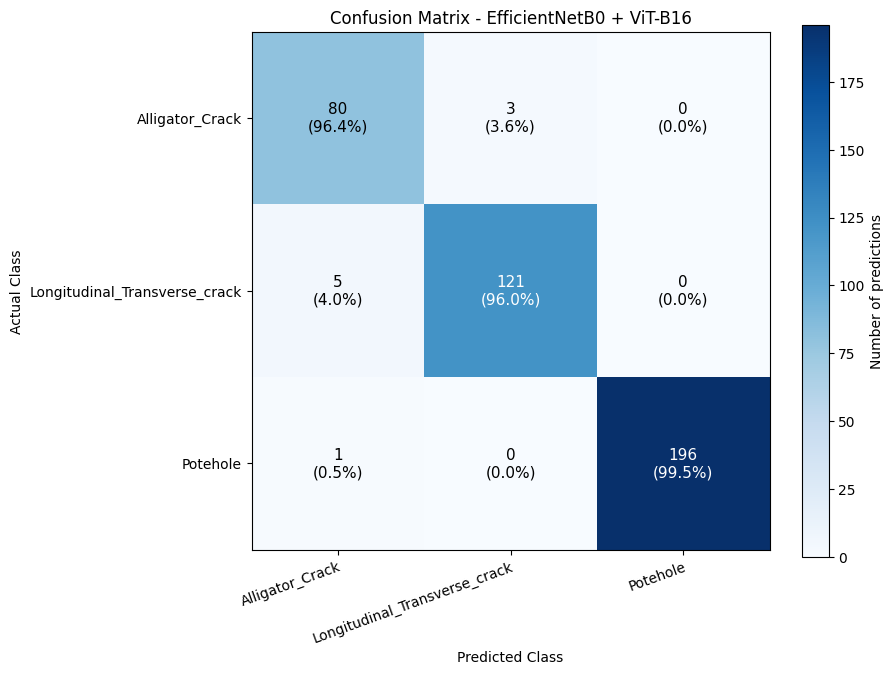

Confusion matrix saved to:
/content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/hybrid_confusion_matrix.png


In [62]:

# ==========================================
# STEP 9: CONFUSION MATRIX VISUALIZATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import os

# Calculate row-normalized percentages
cm_percent = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax, label="Number of predictions")

# Axis labels
ax.set(
    xticks=np.arange(len(CLASS_NAMES)),
    yticks=np.arange(len(CLASS_NAMES)),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted Class",
    ylabel="Actual Class",
    title="Confusion Matrix - EfficientNetB0 + ViT-B16"
)

plt.setp(
    ax.get_xticklabels(),
    rotation=20,
    ha="right",
    rotation_mode="anchor"
)

# Add count and percentage annotations
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i,
            f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=11
        )

fig.tight_layout()

# Save visualization
CONFUSION_PATH = os.path.join(
    RESULTS_PATH,
    "hybrid_confusion_matrix.png"
)

plt.savefig(CONFUSION_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:")
print(CONFUSION_PATH)



FEATURE EXTRACTION COMPLETE
Feature shape: (406, 256)
Labels shape: (406,)


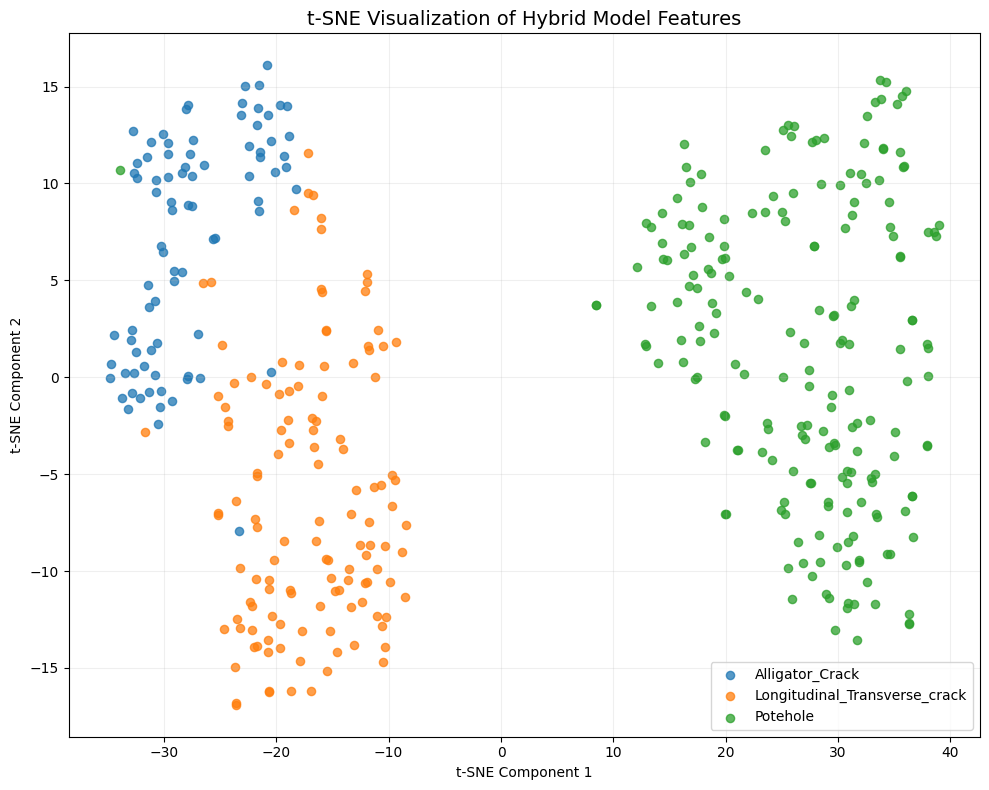


t-SNE visualization saved:
/content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/hybrid_tsne_visualization.png


In [63]:

# ==========================================
# STEP 10: t-SNE FEATURE VISUALIZATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.manifold import TSNE
from tensorflow.keras.models import Model

# Extract features from the adaptive fusion layer
feature_extractor = Model(
    inputs=hybrid_model.input,
    outputs=hybrid_model.get_layer("adaptive_fusion").output
)

# Extract test features and labels
feature_list = []
label_list = []

for images, labels in test_dataset:
    features = feature_extractor.predict(images, verbose=0)
    feature_list.append(features)
    label_list.append(labels.numpy())

X_features = np.concatenate(feature_list, axis=0)
y_labels = np.concatenate(label_list, axis=0)

print("FEATURE EXTRACTION COMPLETE")
print("============================")
print("Feature shape:", X_features.shape)
print("Labels shape:", y_labels.shape)

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_features)

# Plot t-SNE
plt.figure(figsize=(10, 8))

for class_id, class_name in enumerate(CLASS_NAMES):
    indices = y_labels == class_id

    plt.scatter(
        X_tsne[indices, 0],
        X_tsne[indices, 1],
        label=class_name,
        alpha=0.75,
        s=35
    )

plt.title(
    "t-SNE Visualization of Hybrid Model Features",
    fontsize=14
)
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

# Save figure
TSNE_PATH = os.path.join(
    RESULTS_PATH,
    "hybrid_tsne_visualization.png"
)

plt.savefig(TSNE_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("\nt-SNE visualization saved:")
print(TSNE_PATH)


In [64]:

# ==========================================
# STEP 11: INSPECT MODEL LAYERS FOR GRAD-CAM
# ==========================================

print("HYBRID MODEL LAYERS")
print("===================")

for layer in hybrid_model.layers:
    print(
        f"{layer.name:35s}",
        layer.output.shape if hasattr(layer, "output") else ""
    )

print("\nEFFICIENTNET CONVOLUTIONAL LAYERS")
print("=================================")

for layer in efficientnet.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        print(layer.name, layer.output.shape)


HYBRID MODEL LAYERS
road_damage_image                   (None, 224, 224, 3)
road_damage_augmentation            (None, 224, 224, 3)
vi_t_image_classifier_preprocessor  (None, 224, 224, 3)
vi_t_backbone                       (None, 197, 768)
efficientnetb0                      (None, 1280)
vit_cls_token                       (None, 768)
cnn_projection                      (None, 256)
vit_projection                      (None, 256)
layer_normalization                 (None, 256)
layer_normalization_1               (None, 256)
concatenate                         (None, 512)
adaptive_fusion_gate                (None, 256)
complementary_gate                  (None, 256)
multiply                            (None, 256)
multiply_1                          (None, 256)
adaptive_fusion                     (None, 256)
dense                               (None, 128)
dropout_13                          (None, 128)
road_damage_classification          (None, 3)

EFFICIENTNET CONVOLUTIONAL LAYERS
stem_

GRAD-CAM PREDICTION
Actual class: Alligator_Crack
Predicted class: Alligator_Crack
Prediction confidence: 99.96%


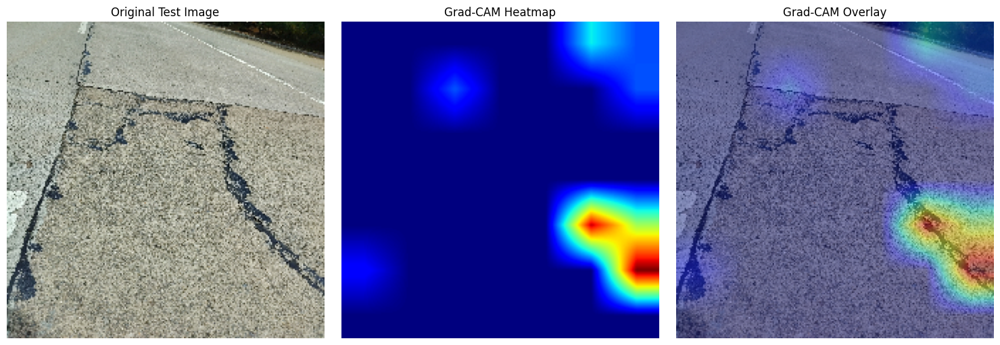


Grad-CAM saved to:
/content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/hybrid_gradcam_sample.png


In [65]:

# ==========================================
# STEP 12: GRAD-CAM FOR THE HYBRID MODEL
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.models import Model

# 1. Connect to EfficientNet's final convolutional layer
efficientnet_cam = Model(
    inputs=efficientnet.input,
    outputs=[
        efficientnet.get_layer("top_conv").output,
        efficientnet.output
    ]
)

# 2. Retrieve the existing trained hybrid-model layers
aug_layer = hybrid_model.get_layer("road_damage_augmentation")
preprocessor_layer = hybrid_model.get_layer(
    "vi_t_image_classifier_preprocessor"
)
vit_layer = hybrid_model.get_layer("vi_t_backbone")
vit_cls_layer = hybrid_model.get_layer("vit_cls_token")

cnn_projection_layer = hybrid_model.get_layer("cnn_projection")
vit_projection_layer = hybrid_model.get_layer("vit_projection")

norm_cnn = hybrid_model.get_layer("layer_normalization")
norm_vit = hybrid_model.get_layer("layer_normalization_1")

concat_layer = hybrid_model.get_layer("concatenate")
gate_layer = hybrid_model.get_layer("adaptive_fusion_gate")
complement_layer = hybrid_model.get_layer("complementary_gate")

multiply_cnn = hybrid_model.get_layer("multiply")
multiply_vit = hybrid_model.get_layer("multiply_1")

fusion_layer = hybrid_model.get_layer("adaptive_fusion")
dense_layer = hybrid_model.get_layer("dense")
dropout_layer = hybrid_model.get_layer("dropout_13")
classifier_layer = hybrid_model.get_layer("road_damage_classification")


# 3. Grad-CAM function
def generate_hybrid_gradcam(image, class_index=None):

    image_batch = tf.cast(image[None, ...], tf.float32)

    # Disable augmentation for visualization
    augmented = aug_layer(image_batch, training=False)

    with tf.GradientTape() as tape:

        # EfficientNet convolutional features
        conv_maps, cnn_features = efficientnet_cam(
            augmented,
            training=False
        )

        # Watch convolutional activations for gradients
        tape.watch(conv_maps)

        # CNN branch
        cnn_proj = cnn_projection_layer(cnn_features)
        cnn_proj = norm_cnn(cnn_proj)

        # ViT branch
        vit_input = preprocessor_layer(augmented)
        vit_tokens = vit_layer(vit_input, training=False)
        vit_cls = vit_cls_layer(vit_tokens)

        vit_proj = vit_projection_layer(vit_cls)
        vit_proj = norm_vit(vit_proj)

        # Adaptive feature fusion
        combined = concat_layer([cnn_proj, vit_proj])
        gate = gate_layer(combined)
        complement = complement_layer(gate)

        cnn_weighted = multiply_cnn([gate, cnn_proj])
        vit_weighted = multiply_vit([complement, vit_proj])

        fused = fusion_layer([cnn_weighted, vit_weighted])

        # Classification head
        x = dense_layer(fused)
        x = dropout_layer(x, training=False)
        probabilities = classifier_layer(x)

        # Select target class
        if class_index is None:
            class_index = int(
                tf.argmax(probabilities[0]).numpy()
            )

        class_score = probabilities[:, class_index]

    # 4. Calculate gradients
    gradients = tape.gradient(class_score, conv_maps)

    if gradients is None:
        raise RuntimeError(
            "Gradients could not be calculated. "
            "Check the Grad-CAM model connections."
        )

    # 5. Calculate Grad-CAM heatmap
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    feature_maps = conv_maps[0]

    weights = pooled_gradients[0]

    heatmap = tf.reduce_sum(
        feature_maps * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    ).numpy().squeeze()

    return (
        heatmap,
        probabilities.numpy()[0],
        class_index
    )


# 6. Get one test image
for images, labels in test_dataset.take(1):
    sample_image = images[0].numpy()
    actual_label = int(labels[0].numpy())

# 7. Generate Grad-CAM
heatmap, probabilities, predicted_class = (
    generate_hybrid_gradcam(sample_image)
)

# 8. Display results
print("GRAD-CAM PREDICTION")
print("===================")
print("Actual class:", CLASS_NAMES[actual_label])
print("Predicted class:", CLASS_NAMES[predicted_class])
print(
    "Prediction confidence:",
    f"{probabilities[predicted_class] * 100:.2f}%"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sample_image.astype("uint8"))
axes[0].set_title("Original Test Image")
axes[0].axis("off")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(sample_image.astype("uint8"))
axes[2].imshow(heatmap, cmap="jet", alpha=0.4)
axes[2].set_title("Grad-CAM Overlay")
axes[2].axis("off")

plt.tight_layout()

# 9. Save visualization
GRADCAM_PATH = os.path.join(
    RESULTS_PATH,
    "hybrid_gradcam_sample.png"
)

plt.savefig(
    GRADCAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrad-CAM saved to:")
print(GRADCAM_PATH)


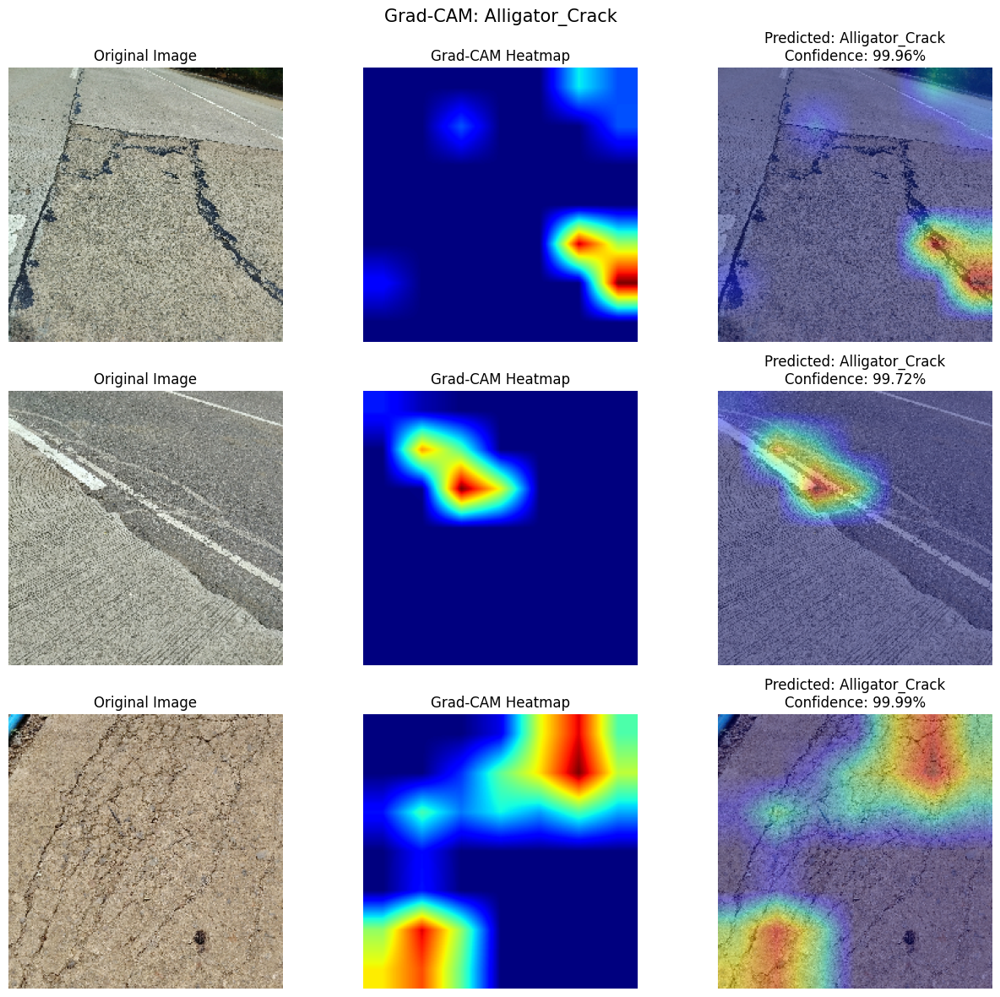

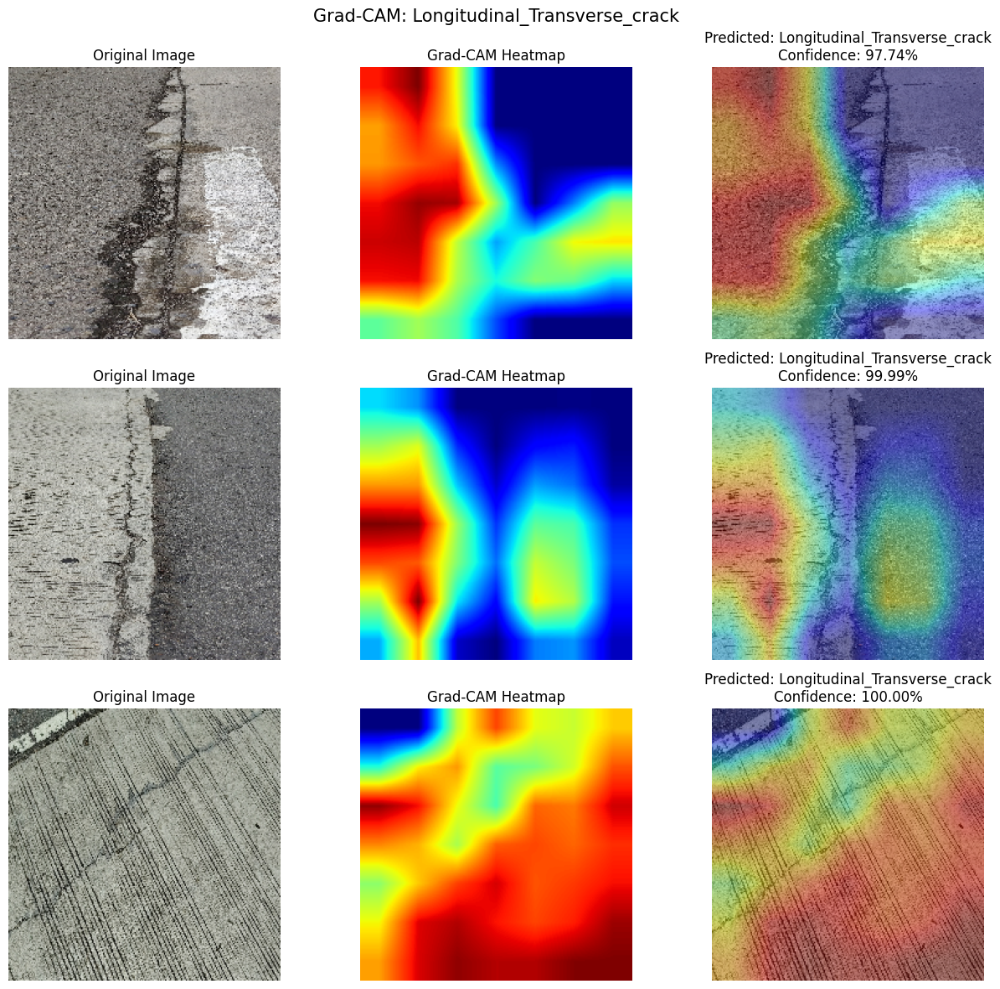

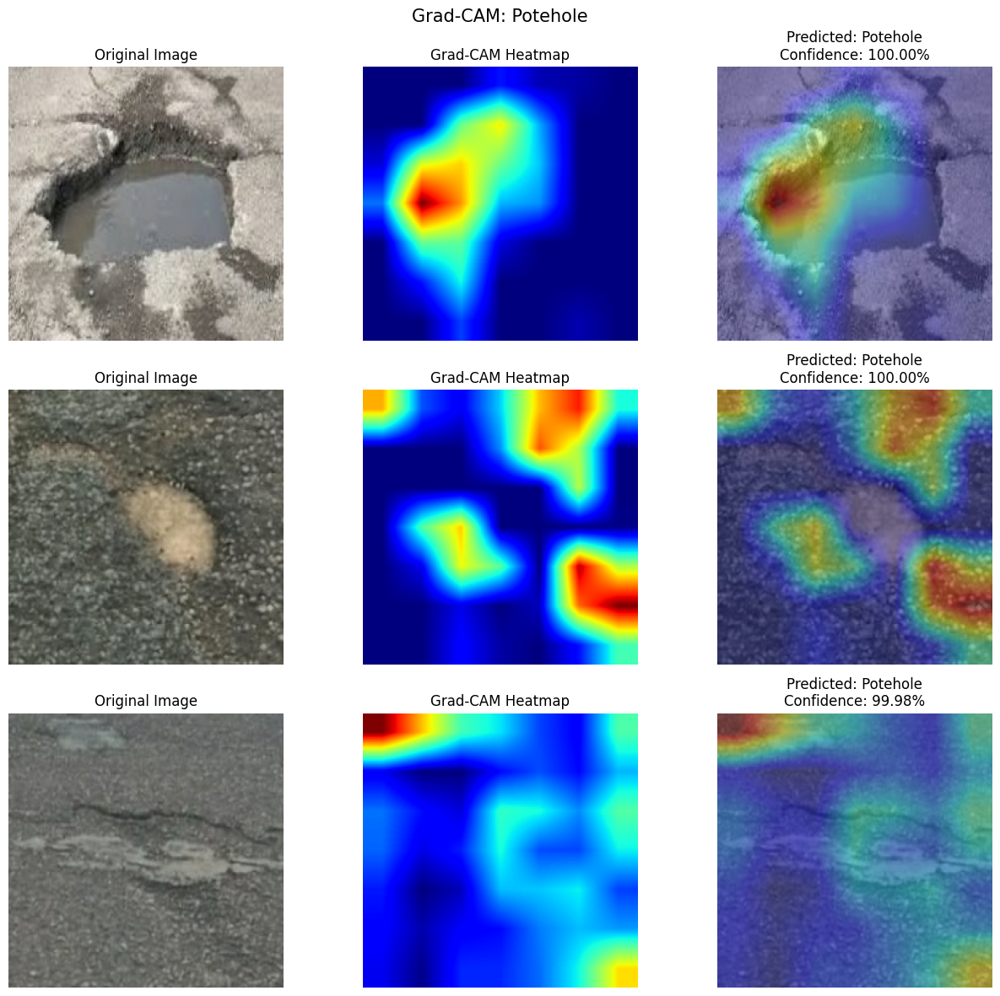


MULTI-CLASS GRAD-CAM COMPLETE
Saved to: /content/drive/MyDrive/yolo/extracted_data/model_results_hybrid/gradcam_all_classes
Alligator_Crack : 3 examples
Longitudinal_Transverse_crack : 3 examples
Potehole : 3 examples


In [66]:

# ==========================================
# STEP 13: MULTI-CLASS GRAD-CAM
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import os

GRADCAM_DIR = os.path.join(
    RESULTS_PATH,
    "gradcam_all_classes"
)

os.makedirs(GRADCAM_DIR, exist_ok=True)

# Collect representative test examples
examples = {i: [] for i in range(3)}

for images, labels in test_dataset:
    predictions = hybrid_model.predict(
        images, verbose=0
    )

    predicted_labels = np.argmax(
        predictions, axis=1
    )

    for i in range(len(labels)):
        actual = int(labels[i].numpy())

        if len(examples[actual]) < 3:
            examples[actual].append({
                "image": images[i].numpy(),
                "actual": actual,
                "predicted": int(predicted_labels[i]),
                "correct": actual == predicted_labels[i]
            })

    if all(len(v) >= 3 for v in examples.values()):
        break

# Generate visualizations
for class_id, class_examples in examples.items():

    fig, axes = plt.subplots(
        len(class_examples),
        3,
        figsize=(13, 4 * len(class_examples))
    )

    if len(class_examples) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, example in enumerate(class_examples):

        image = example["image"]

        heatmap, probabilities, predicted = (
            generate_hybrid_gradcam(image)
        )

        confidence = probabilities[predicted] * 100

        axes[row, 0].imshow(image.astype("uint8"))
        axes[row, 0].set_title("Original Image")

        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title("Grad-CAM Heatmap")

        axes[row, 2].imshow(image.astype("uint8"))
        axes[row, 2].imshow(
            heatmap, cmap="jet", alpha=0.4
        )

        axes[row, 2].set_title(
            f"Predicted: {CLASS_NAMES[predicted]}\n"
            f"Confidence: {confidence:.2f}%"
        )

        for ax in axes[row]:
            ax.axis("off")

    fig.suptitle(
        f"Grad-CAM: {CLASS_NAMES[class_id]}",
        fontsize=15
    )

    plt.tight_layout()

    save_path = os.path.join(
        GRADCAM_DIR,
        f"gradcam_{class_id}_{CLASS_NAMES[class_id]}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nMULTI-CLASS GRAD-CAM COMPLETE")
print("Saved to:", GRADCAM_DIR)

for class_id, items in examples.items():
    print(CLASS_NAMES[class_id], ":", len(items), "examples")


In [67]:

# ==========================================
# CHECK YOLO TRAINING RESULTS IN GOOGLE COLAB
# ==========================================

import os
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Search locations
SEARCH_PATHS = [
    Path("/content/runs"),
    Path("/content/drive/MyDrive/yolo"),
    Path("/content/drive/MyDrive")
]

# Expected YOLO output files
expected_files = [
    "args.yaml",
    "results.csv",
    "results.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxPR_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "labels.jpg",
    "train_batch0.jpg",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg"
]

# Locate YOLO checkpoints
checkpoints = []

for root in SEARCH_PATHS:
    if root.exists():
        checkpoints.extend(root.rglob("best.pt"))

print("YOLO CHECKPOINTS FOUND")
print("=" * 50)

for checkpoint in checkpoints:
    print(checkpoint)

# Locate folders containing YOLO results
result_folders = set()

for root in SEARCH_PATHS:
    if root.exists():
        for file in root.rglob("results.csv"):
            result_folders.add(file.parent)

print("\nYOLO RESULTS FOLDERS")
print("=" * 50)

for folder in sorted(result_folders):
    print("\nFolder:", folder)

    for filename in expected_files:
        filepath = folder / filename

        if filepath.exists():
            print("[FOUND]   ", filename)
        else:
            print("[MISSING] ", filename)

print("\nTOTAL CHECKPOINTS:", len(checkpoints))
print("TOTAL RESULTS FOLDERS:", len(result_folders))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
YOLO CHECKPOINTS FOUND

YOLO RESULTS FOLDERS

TOTAL CHECKPOINTS: 0
TOTAL RESULTS FOLDERS: 0


In [68]:

import os

BASE = "/content/drive/MyDrive"

keywords = [
    "best.pt",
    "last.pt",
    "results.csv",
    "confusion_matrix.png",
    "args.yaml"
]

print("SEARCHING GOOGLE DRIVE...")
print("=" * 60)

found = []

for root, dirs, files in os.walk(BASE):
    # Skip common unnecessary folders
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "node_modules"]
    ]

    for filename in files:
        if filename in keywords:
            path = os.path.join(root, filename)
            found.append(path)
            print("[FOUND]", path)

print("\nTOTAL MATCHING FILES:", len(found))

if not found:
    print("No YOLO result files found in MyDrive.")


SEARCHING GOOGLE DRIVE...
[FOUND] /content/drive/MyDrive/yolo/extracted_data/model_results/confusion_matrix.png

TOTAL MATCHING FILES: 1


In [69]:

import os

project_path = "/content/drive/MyDrive/yolo"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files[:15]:
        print(f"{indent}    {filename}")


yolo/
    data.zip.zip
    extracted_data/
        classes.txt
        notes.json
        images/
            0c966e82-725546666_1554329196292039_1166760418560443054_n.jpg
            0cf3d91c-IMG_20260930_121016_-_Copy.jpg
            0d72dd20-IMG_20260930_120959.jpg
            0da36dd2-AdobeStock_201419293.webp
            0dd3e74d-IMG_20260930_121531.jpg
            0e0e26cf-IMG_20260930_130040.jpg
            0e2cb0c9-istockphoto-174662203-612x612.jpg
            0e391b32-IMG_20260930_124252.jpg
            0e51578b-IMG_20260930_121424.jpg
            0ed7ba1c-IMG_20260930_121022_-_Copy.jpg
            0ef77d10-IMG_20260930_121746_1.jpg
            0efcca0e-IMG_20260930_120144_-_Copy.jpg
            0f44796c-IMG_20260930_115951.jpg
            0f5b89a6-IMG_20260930_124042.jpg
            0f66e279-730049057_894525669612004_2330127696257630095_n.jpg
        labels/
            0002a5ff-IMG_20260930_121742.txt
            00814c5f-727641472_865884816107721_464096325306846257_n.txt
  

In [70]:

import os

BASE = "/content/drive/MyDrive/yolo"

print("SEARCHING FOR YOLOv11s FILES")
print("=" * 50)

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith((".pt", ".yaml", ".yml", ".csv")):
            print(os.path.join(root, file))


SEARCHING FOR YOLOv11s FILES
/content/drive/MyDrive/yolo/extracted_data/model_results/test_metrics.csv
/content/drive/MyDrive/yolo/extracted_data/roi_dataset/roi_manifest.csv
/content/drive/MyDrive/yolo/extracted_data/roi_dataset_70_10_20/roi_manifest_70_10_20.csv


In [71]:

import pandas as pd
import os

file_path = (
    "/content/drive/MyDrive/yolo/extracted_data/"
    "model_results/test_metrics.csv"
)

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("EXISTING TEST METRICS")
    print("=" * 60)
    print(df.to_string(index=False))

    print("\nCOLUMNS:")
    print(df.columns.tolist())

else:
    print("test_metrics.csv not found")


EXISTING TEST METRICS
         Metric    Score
  Test Accuracy 0.892019
Macro Precision 0.892130
   Macro Recall 0.893738
 Macro F1-score 0.892825

COLUMNS:
['Metric', 'Score']


In [72]:

import os

BASE = "/content/drive/MyDrive/yolo"

print("SEARCHING FOR YOLO ANNOTATIONS")
print("=" * 50)

txt_files = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith(".txt"):
            txt_files.append(os.path.join(root, file))

print("Total TXT files:", len(txt_files))

for path in txt_files[:20]:
    print(path)


SEARCHING FOR YOLO ANNOTATIONS
Total TXT files: 1499
/content/drive/MyDrive/yolo/extracted_data/classes.txt
/content/drive/MyDrive/yolo/extracted_data/labels/0002a5ff-IMG_20260930_121742.txt
/content/drive/MyDrive/yolo/extracted_data/labels/00814c5f-727641472_865884816107721_464096325306846257_n.txt
/content/drive/MyDrive/yolo/extracted_data/labels/00c8f29c-pothole-on-asphalt-road-filled-with-rainwater-free-photo.txt
/content/drive/MyDrive/yolo/extracted_data/labels/00ea9ac2-IMG_20260930_120903.txt
/content/drive/MyDrive/yolo/extracted_data/labels/01074905-images_39.txt
/content/drive/MyDrive/yolo/extracted_data/labels/010f8b17-IMG_20260930_121703.txt
/content/drive/MyDrive/yolo/extracted_data/labels/0135878c-IMG_20260930_122200.txt
/content/drive/MyDrive/yolo/extracted_data/labels/01efcb69-images_7.txt
/content/drive/MyDrive/yolo/extracted_data/labels/01fd75c8-IMG_20260930_122733.txt
/content/drive/MyDrive/yolo/extracted_data/labels/01fdfd8a-images_4.txt
/content/drive/MyDrive/yolo/ex

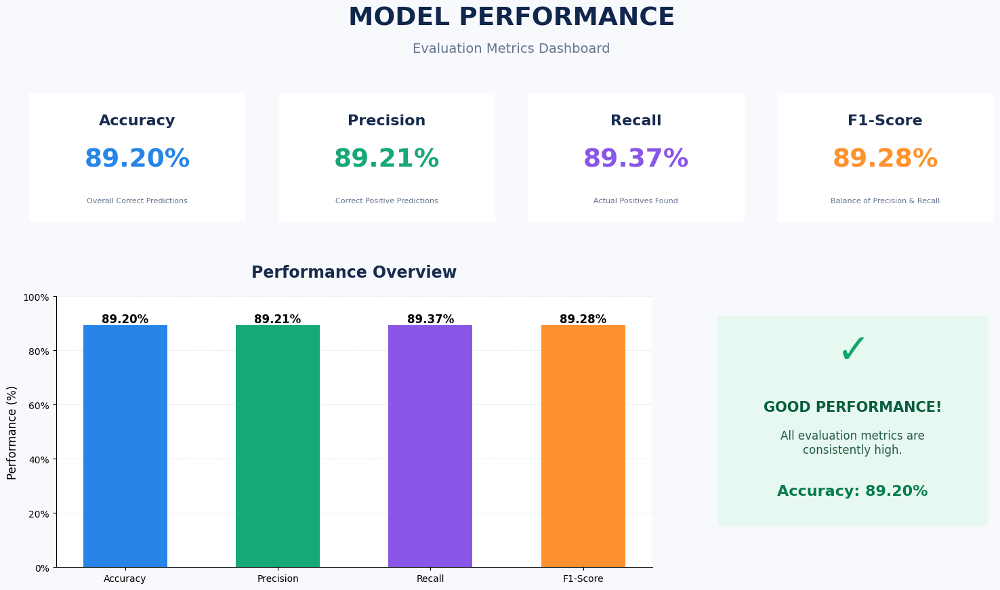

Dashboard successfully generated!
Saved as model_performance_dashboard.png


In [73]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ==========================================
# 1. MODEL EVALUATION METRICS
# ==========================================

metrics = {
    "Accuracy": 0.892019,
    "Precision": 0.892130,
    "Recall": 0.893738,
    "F1-Score": 0.892825
}

names = list(metrics.keys())
scores = [v * 100 for v in metrics.values()]

# Colors
colors = ["#2785E8", "#16A875", "#8956E8", "#FF922E"]

# ==========================================
# 2. CREATE DASHBOARD
# ==========================================

fig = plt.figure(figsize=(16, 10), facecolor="#F7F9FC")

# Main title
fig.text(
    0.5, 0.94,
    "MODEL PERFORMANCE",
    fontsize=27,
    fontweight="bold",
    color="#10264D",
    ha="center"
)

fig.text(
    0.5, 0.90,
    "Evaluation Metrics Dashboard",
    fontsize=14,
    color="#64748B",
    ha="center"
)

# ==========================================
# 3. METRIC CARDS
# ==========================================

card_positions = [
    (0.055, 0.65),
    (0.285, 0.65),
    (0.515, 0.65),
    (0.745, 0.65)
]

for i, (name, score, color) in enumerate(
    zip(names, scores, colors)
):

    x, y = card_positions[i]

    ax = fig.add_axes([x, y, 0.20, 0.19])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Card background
    card = patches.FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.025,rounding_size=0.08",
        facecolor="white",
        edgecolor=color,
        linewidth=2
    )
    ax.add_patch(card)

    # Metric name
    ax.text(
        0.5, 0.75, name,
        ha="center",
        fontsize=16,
        fontweight="bold",
        color="#172B4D"
    )

    # Score
    ax.text(
        0.5, 0.43,
        f"{score:.2f}%",
        ha="center",
        fontsize=27,
        fontweight="bold",
        color=color
    )

    # Bottom description
    descriptions = [
        "Overall Correct Predictions",
        "Correct Positive Predictions",
        "Actual Positives Found",
        "Balance of Precision & Recall"
    ]

    ax.text(
        0.5, 0.15,
        descriptions[i],
        ha="center",
        fontsize=8,
        color="#64748B"
    )

# ==========================================
# 4. PERFORMANCE BAR CHART
# ==========================================

ax_chart = fig.add_axes([0.08, 0.14, 0.55, 0.40])

bars = ax_chart.bar(
    names,
    scores,
    color=colors,
    width=0.55
)

ax_chart.set_ylim(0, 100)
ax_chart.set_ylabel("Performance (%)", fontsize=12)
ax_chart.set_title(
    "Performance Overview",
    fontsize=17,
    fontweight="bold",
    color="#172B4D",
    pad=20
)

ax_chart.set_yticks(np.arange(0, 101, 20))
ax_chart.set_yticklabels(
    [f"{i}%" for i in range(0, 101, 20)]
)

ax_chart.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax_chart.set_axisbelow(True)

for bar, score in zip(bars, scores):
    ax_chart.text(
        bar.get_x() + bar.get_width() / 2,
        score + 1,
        f"{score:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Remove unnecessary borders
ax_chart.spines["top"].set_visible(False)
ax_chart.spines["right"].set_visible(False)

# ==========================================
# 5. PERFORMANCE SUMMARY CARD
# ==========================================

ax_summary = fig.add_axes([0.69, 0.20, 0.25, 0.31])
ax_summary.axis("off")

summary_card = patches.FancyBboxPatch(
    (0, 0), 1, 1,
    boxstyle="round,pad=0.025,rounding_size=0.06",
    facecolor="#E6F8EF",
    edgecolor="#25B878",
    linewidth=2
)

ax_summary.add_patch(summary_card)

ax_summary.text(
    0.5, 0.78,
    "✓",
    ha="center",
    fontsize=43,
    color="#13A66B",
    fontweight="bold"
)

ax_summary.text(
    0.5, 0.55,
    "GOOD PERFORMANCE!",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#075C3D"
)

ax_summary.text(
    0.5, 0.35,
    "All evaluation metrics are\nconsistently high.",
    ha="center",
    fontsize=12,
    color="#245B48"
)

ax_summary.text(
    0.5, 0.15,
    f"Accuracy: {scores[0]:.2f}%",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#087B50"
)

# ==========================================
# 6. SAVE DASHBOARD
# ==========================================

plt.savefig(
    "model_performance_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Dashboard successfully generated!")
print("Saved as model_performance_dashboard.png")


In [74]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 9.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [75]:

from ultralytics import YOLO
from pathlib import Path
import os

# =====================================
# LOAD YOUR TRAINED YOLO MODEL
# =====================================

model_path = "/content/drive/MyDrive/yolo/runs/detect/train/weights/best.pt"

data_yaml = "/content/drive/MyDrive/yolo/extracted_data/data.yaml"

model = YOLO(model_path)

# =====================================
# RUN MODEL VALIDATION
# =====================================

results = model.val(
    data=data_yaml,
    split="test",       # Change to "val" if no test split exists
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True
)

# =====================================
# DISPLAY EVALUATION METRICS
# =====================================

print("\n========== YOLO MODEL PERFORMANCE ==========")

print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)

# =====================================
# DISPLAY SAVED RESULTS DIRECTORY
# =====================================

save_dir = Path(results.save_dir)

print("\n========== GENERATED EVALUATION GRAPHS ==========")
print("Results folder:", save_dir)

for file in save_dir.iterdir():
    if file.suffix.lower() == ".png":
        print(file.name)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/yolo/runs/detect/train/weights/best.pt'

In [76]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [79]:
print("Checking trained model...")

if "model" in globals():
    print("Trained model variable found!")
    print(model)
else:
    print("No active model variable found.")

Checking trained model...
Trained model variable found!
<Functional name=functional_1, built=True>


In [81]:
print("MODEL TYPE:", type(model))
print("MODEL CLASS:", model.__class__.__name__)

print("\nMODEL SUMMARY:")
model.summary()

MODEL TYPE: <class 'keras.src.models.functional.Functional'>
MODEL CLASS: Functional

MODEL SUMMARY:


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,061,102 (15.49 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 7,688 (30.04 KB)

In [84]:

import numpy as np
import tensorflow as tf

# Get actual labels and predictions from test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)

# Convert one-hot labels into class indices if needed
if len(y_true.shape) > 1 and y_true.shape[-1] > 1:
    y_true = np.argmax(y_true, axis=1)
else:
    y_true = y_true.flatten().astype(int)

# Predicted classes
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predictions shape:", y_pred.shape)
print("Class names:", class_names)
print("Predictions generated successfully!")


13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 554ms/step
Actual labels shape: (406,)
Predictions shape: (406,)
Class names: ['Alligator Crack', 'Longitudinal/Transverse crack', 'Potehole']
Predictions generated successfully!



========== MODEL PERFORMANCE ==========
Accuracy:  0.807882
Precision: 0.791150
Recall:    0.828631
F1-score:  0.796714

CLASSIFICATION REPORT
                               precision    recall  f1-score   support

              Alligator Crack       0.65      0.96      0.78        83
Longitudinal/Transverse crack       0.75      0.73      0.74       126
                     Potehole       0.97      0.79      0.87       197

                     accuracy                           0.81       406
                    macro avg       0.79      0.83      0.80       406
                 weighted avg       0.84      0.81      0.81       406



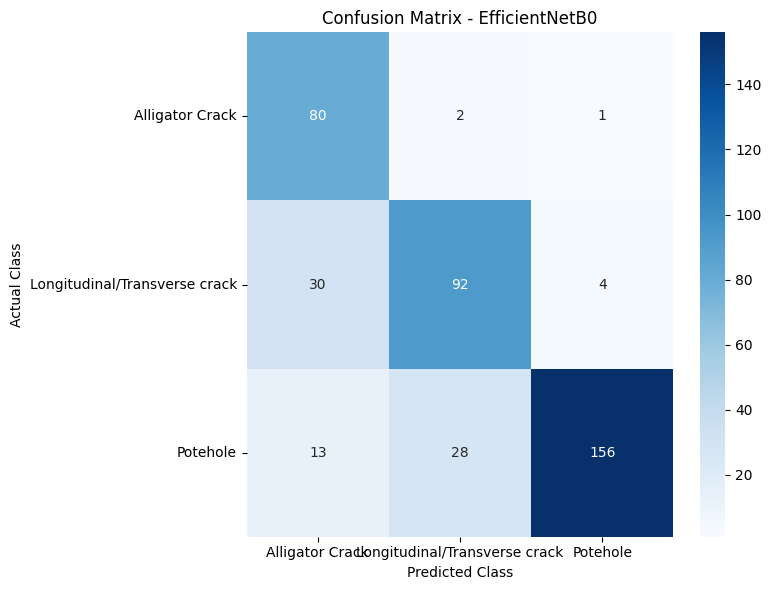

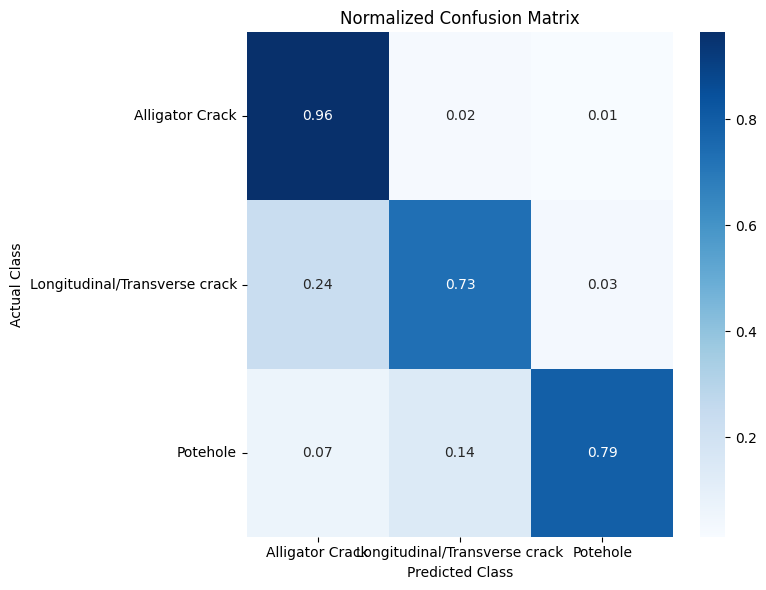

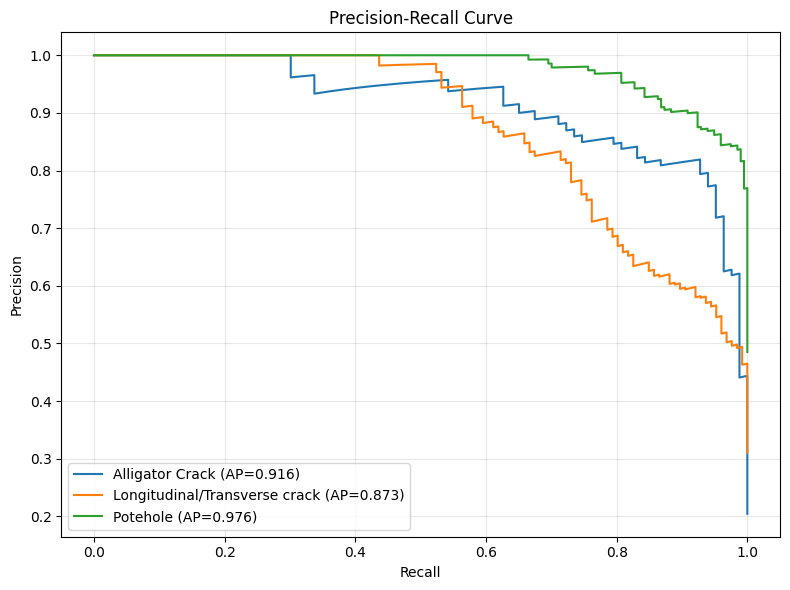

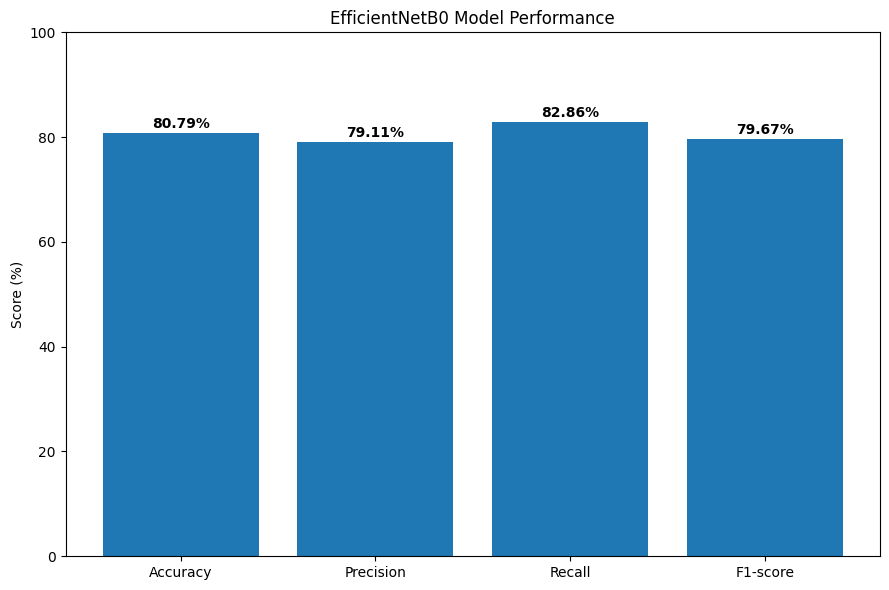


ALL EVALUATIONS COMPLETED!
Saved to: /content/efficientnet_evaluation


In [85]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)

from sklearn.preprocessing import label_binarize

# Create output folder
output_dir = Path("/content/efficientnet_evaluation")
output_dir.mkdir(exist_ok=True)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("\n========== MODEL PERFORMANCE ==========")
print(f"Accuracy:  {accuracy:.6f}")
print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1-score:  {f1:.6f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    zero_division=0
))

# ======================================
# 1. CONFUSION MATRIX
# ======================================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - EfficientNetB0")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=300)
plt.show()

# ======================================
# 2. NORMALIZED CONFUSION MATRIX
# ======================================

cm_norm = confusion_matrix(
    y_true, y_pred, normalize="true"
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(
    output_dir / "confusion_matrix_normalized.png",
    dpi=300
)
plt.show()

# ======================================
# 3. PRECISION-RECALL CURVE
# ======================================

y_binary = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(class_names):
    p, r, _ = precision_recall_curve(
        y_binary[:, i], y_prob[:, i]
    )

    ap = average_precision_score(
        y_binary[:, i], y_prob[:, i]
    )

    plt.plot(r, p, label=f"{class_name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "PR_curve.png", dpi=300)
plt.show()

# ======================================
# 4. CLASSIFICATION METRICS SUMMARY
# ======================================

metric_names = [
    "Accuracy", "Precision", "Recall", "F1-score"
]

metric_values = [
    accuracy, precision, recall, f1
]

plt.figure(figsize=(9, 6))
bars = plt.bar(
    metric_names,
    np.array(metric_values) * 100
)

plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.title("EfficientNetB0 Model Performance")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value*100:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(output_dir / "performance_metrics.png", dpi=300)
plt.show()

# ======================================
# 5. SAVE METRICS
# ======================================

import pandas as pd

metrics_df = pd.DataFrame({
    "Metric": metric_names,
    "Score": metric_values
})

metrics_df.to_csv(
    output_dir / "evaluation_metrics.csv",
    index=False
)

print("\nALL EVALUATIONS COMPLETED!")
print("Saved to:", output_dir)


In [86]:
import shutil
import os

source = "/content/efficientnet_evaluation"
destination = "/content/drive/MyDrive/yolo/extracted_data/evaluation_results"

os.makedirs(destination, exist_ok=True)

for file in os.listdir(source):
    shutil.copy2(
        os.path.join(source, file),
        os.path.join(destination, file)
    )

print("Evaluation files successfully saved!")
print("Location:", destination)

Evaluation files successfully saved!
Location: /content/drive/MyDrive/yolo/extracted_data/evaluation_results


In [2]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

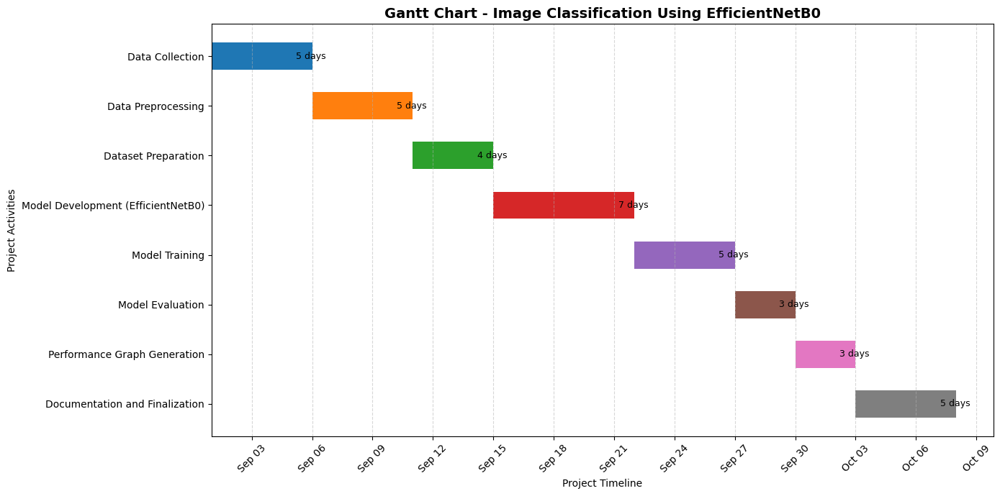

Gantt chart saved successfully!
Location: /content/drive/MyDrive/yolo/extracted_data/evaluation_results/gantt_chart.png


In [88]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import os
from datetime import datetime

# =====================================
# PROJECT GANTT CHART
# =====================================

tasks = [
    ("Data Collection", "2026-09-01", "2026-09-05"),
    ("Data Preprocessing", "2026-09-06", "2026-09-10"),
    ("Dataset Preparation", "2026-09-11", "2026-09-14"),
    ("Model Development (EfficientNetB0)", "2026-09-15", "2026-09-21"),
    ("Model Training", "2026-09-22", "2026-09-26"),
    ("Model Evaluation", "2026-09-27", "2026-09-29"),
    ("Performance Graph Generation", "2026-09-30", "2026-10-02"),
    ("Documentation and Finalization", "2026-10-03", "2026-10-07")
]

# Convert dates
df = pd.DataFrame(tasks, columns=["Task", "Start", "End"])
df["Start"] = pd.to_datetime(df["Start"])
df["End"] = pd.to_datetime(df["End"])

# Calculate duration
df["Duration"] = (df["End"] - df["Start"]).dt.days + 1

# =====================================
# CREATE GANTT CHART
# =====================================

fig, ax = plt.subplots(figsize=(14, 7))

for i, row in df.iterrows():
    ax.barh(
        row["Task"],
        row["Duration"],
        left=mdates.date2num(row["Start"]),
        height=0.55
    )

    # Add duration label
    ax.text(
        mdates.date2num(row["End"]) + 0.2,
        i,
        f'{row["Duration"]} days',
        va="center",
        fontsize=9
    )

# Format chart
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))

plt.xticks(rotation=45)
plt.xlabel("Project Timeline")
plt.ylabel("Project Activities")
plt.title("Gantt Chart - Image Classification Using EfficientNetB0",
          fontsize=14, fontweight="bold")

ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

# =====================================
# SAVE TO GOOGLE DRIVE
# =====================================

save_folder = "/content/drive/MyDrive/yolo/extracted_data/evaluation_results"
os.makedirs(save_folder, exist_ok=True)

save_path = os.path.join(save_folder, "gantt_chart.png")

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Gantt chart saved successfully!")
print("Location:", save_path)

In [89]:
import os

file_path = "/content/drive/MyDrive/yolo/extracted_data/evaluation_results/gantt_chart.png"

if os.path.exists(file_path):
    print("SUCCESS: Gantt chart exists!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("Gantt chart not found. Run Step 2 first.")

SUCCESS: Gantt chart exists!
File size: 253.9 KB


In [1]:
import os

# Create a folder for the trained model
save_folder = "/content/drive/MyDrive/yolo/extracted_data/trained_model"
os.makedirs(save_folder, exist_ok=True)

# Save the trained model
model_path = os.path.join(save_folder, "efficientnetb0_trained.keras")

model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

NameError: name 'model' is not defined

In [18]:
import os

print("========== NOTEBOOK FILES ==========")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

========== NOTEBOOK FILES ==========


#1.&nbsp;Gather and Label Training Images

Before we start training, we need to gather and label images that will be used for training the object detection model. A good starting point for a proof-of-concept model is 200 images. The training images should have random objects in the image along with the desired objects, and should have a variety of backgrounds and lighting conditions.

There are a couple options for gathering images:


*   Build a custom dataset by taking your own pictures of the objects and labeling them (this typically results in the best performance)
*   Find a pre-made dataset from sources like [Roboflow Universe](), [Kaggle](), or [Google Images V7]()


If you want to build your own dataset, there are several tools available for labeling images. One good option is [Label Studio](https://labelstud.io/?utm_source=youtube&utm_medium=video&utm_campaign=edjeelectronics), a free and open-source labeling tool that has a simple workflow while providing capabilities for more advanced features. My YouTube video that walks through this notebook (link to be added soon) shows how to label images with Label Studio.

<p align=center>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/label-studio-example.PNG" height="380"><br>
<i>Example of a candy image labeled with Label Studio.</i>
</p>

If you used Label Studio to label and export the images, they'll be exported in a `project.zip` file that contains the following:

- An `images` folder containing the images
- A `labels` folder containing the labels in YOLO annotation format
- A `classes.txt` labelmap file that contains all the classes
- A `notes.json` file that contains info specific to Label Studio (this file can be ignored)

If you obtained your dataset from another source (like Roboflow Universe) or used another tool to label your dataset, make sure the files are organized in the same folder structure.

<p align=center>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/zipped-data-example.png" height=""><br>
<i>Organize your data in the folders shown here. See my <a href="https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip">Candy Detection Dataset</a> for an example.</i>
</p>

Once you've got your dataset built, put into the file structure shown above, and zipped into `data.zip`, you're ready to move on to the next step.

# 2.&nbsp;Upload Image Dataset and Prepare Training Data

Next, we'll upload our dataset and prepare it for training with YOLO. We'll split the dataset into train and validation folders, and we'll automatically generate the configuration file for training the model.

## 2.1 Upload images

First, we need to upload the dataset to Colab. Here are a few options for moving the `data.zip` folder into this Colab instance.

**Option 1. Upload through Google Colab**

Upload the `data.zip` file to the Google Colab instance by clicking the "Files" icon on the left hand side of the browser, and then the "Upload to session storage" icon. Select the zip folder to upload it.

<p>
<br>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/upload-colab-files.png" height="240">
</p>



**Option 2. Copy from Google Drive**

You can also upload your images to your personal Google Drive, mount the drive on this Colab session, and copy them over to the Colab filesystem. This option works well if you want to upload the images beforehand so you don't have to wait for them to upload each time you restart this Colab. If you have more than 50MB worth of images, I recommend using this option.

First, upload the `data.zip` file to your Google Drive, and make note of the folder you uploaded them to. Replace `MyDrive/path/to/data.zip` with the path to your zip file. (For example, I uploaded the zip file to folder called "candy-dataset1", so I would use `MyDrive/candy-dataset1/data.zip` for the path). Then, run the following block of code to mount your Google Drive to this Colab session and copy the folder to this filesystem.

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

!cp /content/gdrive/MyDrive/path/to/data.zip /content

**Option 3. Use my candy detection or coin detection dataset**

If you just want to test the process on a pre-made dataset, you can use one of my datasets:

*   [Candy image dataset](https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_14DEC24.zip), which contains 162 pictures of popular candies (Skittles, Snickers, etc)
*   [Coin image dataset](https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/YOLO_coin_data_12DEC30.zip), which contains 750 pictures of US coins (pennies, dimes, nickels, and quarters)

Download one of the datasets by running the following code block. I'll use the candy detection dataset as the example for the rest of the notebook.

In [ ]:
# To use my one of pre-made dataset instead of your own custom dataset, download it here (control which dataset is downloaded by commenting out either line)
!wget -O /content/data.zip https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip # Candy dataset
#!wget -O /content/data.zip https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/YOLO_coin_data_12DEC30.zip # Coin dataset

## 2.2 Split images into train and validation folders

At this point, whether you used Option 1, 2, or 3, you should be able to click the folder icon on the left and see your `data.zip` file in the list of files. Next, we'll unzip `data.zip` and create some folders to hold the images. Run the following code block to unzip the data.

In [ ]:
# Unzip images to a custom data folder
!unzip -q /content/data.zip -d /content/custom_data

Ultralytics requires a particular folder structure to store training data for models. Ultralytics requires a particular folder structure to store training data for models. The root folder is named “data”. Inside, there are two main folders:

*   **Train**: These are the actual images used to train the model. In one epoch of training, every image in the train set is passed into the neural network. The training algorithm adjusts the network weights to fit the data in the images.


*   **Validation**: These images are used to check the model's performance at the end of each training epoch.

In each of these folders is a “images” folder and a “labels” folder, which hold the image files and annotation files respectively.


I wrote a Python script that will automatically create the required folder structure and randomly move 90% of dataset to the "train" folder and 10% to the "validation" folder. Run the following code block to download and execute the scrpt.

In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

# TO DO: Improve robustness of train_val_split.py script so it can handle nested data folders, etc
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

# 3.&nbsp;Install Requirements (Ultralytics)

Next, we'll install the Ultralytics library in this Google Colab instance. This Python library will be used to train the YOLO model.

In [ ]:
!pip install ultralytics

# 4.&nbsp;Configure Training


There's one last step before we can run training: we need to create the Ultralytics training configuration YAML file. This file specifies the location of your train and validation data, and it also defines the model's classes. An example configuration file model is available [here](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/datasets/coco128.yaml).

Run the code block below to automatically generate a `data.yaml` configuration file. Make sure you have a labelmap file located at `custom_data/classes.txt`. If you used Label Studio or one of my pre-made datasets, it should already be present. If you assembled the dataset another way, you may have to manually create the `classes.txt` file (see [here](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/doc/classes.txt) for an example of how it's formatted).

In [ ]:
# Python function to automatically create data.yaml config file
# 1. Reads "classes.txt" file to get list of class names
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read class.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Write data to YAML file
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return

# Define path to classes.txt and run function
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

# 5.&nbsp;Train Model

## 5.1 Training Parameters
Now that the data is organized and the config file is created, we're ready to start training! First, there are a few important parameters to decide on. Visit my article on [Training YOLO Models Locally](https://www.ejtech.io/learn/train-yolo-models) to learn more about these parameters and how to choose them.

**Model architecture & size (`model`):**

There are several YOLO11 models sizes available to train, including `yolo11n.pt`, `yolo11s.pt`, `yolo11m.pt`, `yolo11l.pt`, and `yolo11xl.pt`. Larger models run slower but have higher accuracy, while smaller models run faster but have lower accuracy. I made a brief YouTube video that compares performance of different YOLO models on a Raspberry Pi 5 and a laptop with a RTX 4050 GPU, [check it out here to get a sense of their speed accuracy](https://youtu.be/_WKS4E9SmkA). If you aren't sure which model size to use, `yolo11s.pt` is a good starting point.

You can also train YOLOv8 or YOLOv5 models by substituting `yolo11` for `yolov8` or `yolov5`.


**Number of epochs (`epochs`)**

In machine learning, one “epoch” is one single pass through the full training dataset. Setting the number of epochs dictates how long the model will train for. The best amount of epochs to use depends on the size of the dataset and the model architecture. If your dataset has less than 200 images, a good starting point is 60 epochs. If your dataset has more than 200 images, a good starting point is 40 epochs.


**Resolution (`imgsz`)**

Resolution has a large impact on the speed and accuracy of the model: a lower resolution model will have higher speed but less accuracy. YOLO models are typically trained and inferenced at a 640x640 resolution. However, if you want your model to run faster or know you will be working with low-resolution images, try using a lower resolution like 480x480.


## 5.2 Run Training!

Run the following code block to begin training. If you want to use a different model, number of epochs, or resolution, change `model`, `epochs`, or `imgsz`.

In [ ]:
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=60 imgsz=640

The training algorithm will parse the images in the training and validation directories and then start training the model. At the end of each training epoch, the program runs the model on the validation dataset and reports the resulting mAP, precision, and recall. As training continues, the mAP should generally increase with each epoch. Training will end once it goes through the number of epochs specified by `epochs`.

> **NOTE:** Make sure to allow training to run to completion, because an optimizer runs at the end of training that strips out unneeded layers from the model.

The best trained model weights will be saved in `content/runs/detect/train/weights/best.pt`. Additional information about training is saved in the `content/runs/detect/train` folder, including a `results.png` file that shows how loss, precision, recall, and mAP progressed over each epoch.

#6.&nbsp;Test Model

The model has been trained; now it's time to test it! The commands below run the model on the images in the validation folder and then display the results for the first 10 images. This is a good way to confirm your model is working as expected. Click Play on the blocks below to see how your model performs.

In [ ]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')


The model should draw a box around each object of interest in each image. If it isn't doing a good job of detecting objects, here are a few tips:

1. Double-check your dataset to make sure there are no labeling errors or conflicting examples.
2. Increase the number of epochs used for training.
3. Use a larger model size (e.g. `yolo11l.pt`).
4. Add more images to the training dataset. See my [dataset video](https://www.youtube.com/watch?v=v0ssiOY6cfg) for tips on how to capture good training images and improve accuracy.

You can also run the model on video files or other images images by uploading them to this notebook and using the above `!yolo detect predict` command, where `source` points to the location of the video file, image, or folder of images. The results will be saved in `runs/detect/predict`.

Drawing boxes on images is great, but it isn't very useful in itself. It's also not very helpful to just run this models inside a Colab notebook: it's easier if we can just run it on a local computer. Continue to the next section to see how to download your newly trained model and run it on a local device.

#7.&nbsp;Deploy Model

Now that your custom model has been trained, it's ready to be downloaded and deployed in an application! YOLO models can run on a wide variety of hardware, including PCs, embedded systems, and phones. Ultralytics makes it easy to convert the YOLO models to various formats (`tflite`, `onnx`, etc.) and deploy them in a variety of environments.

This section shows how to download the model and provides links to instructions for deploying it on your PC and edge devices like the Raspberry Pi.

## 7.1 Download YOLO Model

First, zip and download the trained model by running the code blocks below.

The code creates a folder named `my_model`, moves the model weights into it, and renames them from `best.pt` to `my_model.pt`. It also adds the training results in case you want to reference them later. It then zips the folder as `my_model.zip`.

In [ ]:
# Create "my_model" folder to store model weights and train results
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Zip into "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

In [ ]:
# This takes forever for some reason, you can also just download the model from the sidebar
from google.colab import files

files.download('/content/my_model.zip')

## 7.2 Deploy YOLO Model on Local Devices

Next, we'll take our downloaded model and run it on a local device. This section provides instructions showing how to deploy YOLO models on various devices.

I wrote a basic Python script, `yolo_detect.py`, that shows how to load a model, run inference on an image source, parse the inference results, and display boxes around each detected class in the image. The [script](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/yolo_detect.py) gives an example of how to work with Ultralytics YOLO models in Python, and it can be used as a starting point for more advanced applications.

### 7.2.1 Deploy on PC (Windows, Linux, or macOS)

The easiest way to run Ultralytics models on a PC is using Anaconda. Anaconda sets up a virtual Python environment and allows you to easily install Ultralytics and PyTorch. It automatically installs CUDA and cuDNN, which allows you to speed up model inference with your NVIDIA GPU.

> **NOTE:** My YouTube video (link to be added) shows how to deploy your model on a PC. It walks through the following steps, so watch the video if you prefer having visual instructions.

**1. Download and Install Anaconda**

Go to the Anaconda download page at https://anaconda.com/download, click the “skip registration” button, and then download the package for your OS. When it's finished downloading, run the installer and click through the installation steps. You can use the default options for installation.

**2. Set up virtual environment**

Once it's installed, run Anaconda Prompt from the Start Bar. (If you're on macOS or Linux, just open a command terminal).

Issue the following commands to create a new Python environment and activate it:

```
conda create --name yolo-env1 python=3.12 -y
conda activate yolo-env1
```

Install Ultralytics (which also installs import libraries like OpenCV-Python, Numpy, and PyTorch) by issuing the following command:

```
pip install ultralytics
```

If you have an NVIDIA GPU, you can install the GPU-enabled version of PyTorch by issuing the following command:

```
pip install --upgrade torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124
```

**3. Extract downloaded model**
Take the `my_model.zip` file you downloaded in Step 7.1 and unzip it to a folder on your PC. In the Anaconda Prompt terminal, move into the unzipped folder using:

```
cd path/to/folder
```

**4. Download and run yolo_detect.py**

Download the `yolo_detect.py` script into the `my_model` folder using:

```
curl -o yolo_detect.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/yolo_detect.py
```

Alright! We're ready to run the script. To run inference with a yolov8s model on a USB camera at 1280x720 resolution, issue:

```
python yolo_detect.py --model my_model.pt --source usb0 --resolution 1280x720
```

A window will appear showing a live feed from your webcam with boxes drawn around detected objects in each frame.

You can also run the model on an video file, image, or folder of images. To see a full list of arguments for `yolo_detect.py`, issue `python yolo_detect.py --help` or see the [README file](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/README.md).




### 7.2.2 Deploy on Raspberry Pi

Keep an eye out for an article showing how to convert YOLO models to NCNN format and run them on the Raspberry Pi!

# 8.&nbsp;Conclusion

Congratulations! You've successfully trained and deployed a YOLO object detection model. 😀

Next, you can extend your application beyond just drawing boxes and counting objects. Add functionality like logging the number of objects detected over time or taking a picture when certain objects are detected. Check out some example applications at our GitHub repository: https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models

Thanks for working through this notebook, and good luck with your projects!

# Appendix: Common Errors

If you run into any errors working through this notebook, please do the following:


- Double-check that the dataset files are set up in the correct folder structure
- Make sure there are no typos or errors in your labelmap file
- Google search the error to look for solutions

If none of those help, please submit an [Issue](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/issues) on the GitHub page. In this section, I will add resolutions to common errors as they come up.